# AirCast — Intelligent Air Quality Prediction System
## Clean end-to-end modeling and final model selection workflow

This notebook continues the completed Beijing Multi-Site Air Quality project for **next-hour PM2.5 prediction**.

It retains the original data-quality checks, EDA, verified next-hour target, gap-aware lag features, chronological splits, and training-only preprocessing. It removes duplicate/commented experiments and avoids retraining all six benchmark models.

The modeling stages then:
1. Verify row-by-row alignment between engineered CSVs and saved processed arrays.
2. Reproduce the six-model validation benchmark table.
3. Analyze Random Forest and cross-model feature importance.
4. Review correlated predictors and test reduced feature sets.
5. Run a small LightGBM tuning experiment without repeating the expensive RandomizedSearchCV.
6. Select a final model using validation metrics.
7. Analyze validation residuals, pollution-level errors and station-level errors.
8. Evaluate the untouched test set once, after model selection.

**Important:** Existing saved model files and processed artifacts in the Google Drive `Dataset` folder are reused. Run cells from top to bottom. Do not use the test set for feature selection or tuning.

In [ ]:
# Mount Google Drive without forcibly unmounting or deleting folders.
from google.colab import drive
drive.mount('/content/drive', force_remount=False)


Mounted at /content/drive


## 1. Setup and paths

The paths below match the current Google Drive project layout. If your folders differ, update `PROJECT_DIR` and `RAW_DIR`.

In [ ]:
from pathlib import Path
import glob
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

RANDOM_STATE = 42
PROJECT_DIR = Path("/content/drive/MyDrive/DSA_B11/Majorproject")
RAW_DIR = PROJECT_DIR / "RawDataset"
DATA_DIR = PROJECT_DIR / "Dataset"
DATA_DIR.mkdir(parents=True, exist_ok=True)

COMBINED_PATH = DATA_DIR / "beijing_air_quality_combined.csv"
TARGET_PREPARED_PATH = DATA_DIR / "beijing_air_quality_target_prepared.csv"

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
print("Project directory exists:", PROJECT_DIR.exists())
print("Raw dataset directory exists:", RAW_DIR.exists())
print("Output directory:", DATA_DIR)

Project directory exists: True
Raw dataset directory exists: True
Output directory: /content/drive/MyDrive/DSA_B11/Majorproject/Dataset


In [ ]:
# Install tree-boosting libraries used by the saved models and tuning stage.
%pip -q install lightgbm xgboost catboost


## 2. Load and combine the station data

If the combined CSV already exists, it is loaded. Otherwise, the 12 station CSV files are combined from `RawDataset`. The station-specific `No` column is not a model feature and is removed.

In [ ]:
if COMBINED_PATH.exists():
    air_df = pd.read_csv(COMBINED_PATH)
    print("Loaded existing combined dataset:", COMBINED_PATH)
else:
    csv_files = sorted(glob.glob(str(RAW_DIR / "*.csv")))
    if not csv_files:
        raise FileNotFoundError(
            f"No station CSV files found in {RAW_DIR}. "
            "Check Google Drive is mounted and update RAW_DIR if needed."
        )

    station_frames = []
    for file in csv_files:
        frame = pd.read_csv(file)
        station_frames.append(frame)
        print(Path(file).name, frame.shape)

    air_df = pd.concat(station_frames, ignore_index=True)
    if "No" in air_df.columns:
        air_df = air_df.drop(columns="No")

    air_df["datetime"] = pd.to_datetime(
        air_df[["year", "month", "day", "hour"]], errors="coerce"
    )
    air_df = air_df.sort_values(["station", "datetime"]).reset_index(drop=True)
    air_df.to_csv(COMBINED_PATH, index=False)
    print("Saved combined dataset:", COMBINED_PATH)

# Standardize datetime and order for both loading paths
if "datetime" not in air_df.columns:
    air_df["datetime"] = pd.to_datetime(
        air_df[["year", "month", "day", "hour"]], errors="coerce"
    )
else:
    air_df["datetime"] = pd.to_datetime(air_df["datetime"], errors="coerce")

if "No" in air_df.columns:
    air_df = air_df.drop(columns="No")
air_df = air_df.sort_values(["station", "datetime"]).reset_index(drop=True)
print("\nCombined shape:", air_df.shape)
print("Stations:", air_df["station"].nunique())
print("Date range:", air_df["datetime"].min(), "to", air_df["datetime"].max())
display(air_df.head())

Loaded existing combined dataset: /content/drive/MyDrive/DSA_B11/Majorproject/Dataset/beijing_air_quality_combined.csv

Combined shape: (420768, 18)
Stations: 12
Date range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin,2013-03-01 01:00:00
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00
3,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin,2013-03-01 03:00:00
4,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin,2013-03-01 04:00:00


## 3. Initial data overview

In [ ]:
print("Shape:", air_df.shape)
print("\nData types:")
display(air_df.dtypes.to_frame("dtype"))
print("\nNumerical summary:")
display(air_df.describe(include="number").T)
print("\nRecords per station:")
display(air_df.groupby("station").size().rename("records").to_frame())

Shape: (420768, 18)

Data types:


,dtype
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64
O3,float64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
year,420768.0,2014.662560,1.177198,2013.0000,2014.00,2015.0,2016.00,2017.0
month,420768.0,6.522930,3.448707,1.0000,4.00,7.0,10.00,12.0
day,420768.0,15.729637,8.800102,1.0000,8.00,16.0,23.00,31.0
hour,420768.0,11.500000,6.922195,0.0000,5.75,11.5,17.25,23.0
PM2.5,412029.0,79.793428,80.822391,2.0000,20.00,55.0,111.00,999.0
PM10,414319.0,104.602618,91.772426,2.0000,36.00,82.0,145.00,999.0
SO2,411747.0,15.830835,21.650603,0.2856,3.00,7.0,20.00,500.0
NO2,408652.0,50.638586,35.127912,1.0265,23.00,43.0,71.00,290.0
CO,400067.0,1230.766454,1160.182716,100.0000,500.00,900.0,1500.00,10000.0
O3,407491.0,57.372271,56.661607,0.2142,11.00,45.0,82.00,1071.0



Records per station:


,records
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064


## 4. Data quality checks

Check duplicate records, duplicate station-time keys, invalid timestamps, and gaps. A gap is not filled by inventing observations; target and lag creation later checks exact time differences.

In [ ]:
print("Exact duplicate rows:", air_df.duplicated().sum())
print("Duplicate station-timestamp pairs:", air_df.duplicated(["station", "datetime"]).sum())
print("Invalid timestamps:", air_df["datetime"].isna().sum())

valid_time_df = air_df.dropna(subset=["datetime"]).sort_values(["station", "datetime"]).copy()
valid_time_df["time_difference"] = valid_time_df.groupby("station")["datetime"].diff()
gaps = valid_time_df[valid_time_df["time_difference"] > pd.Timedelta(hours=1)]
print("Gaps greater than one hour:", len(gaps))
display(gaps.groupby("station").size().reindex(sorted(air_df["station"].dropna().unique()), fill_value=0).rename("gaps_over_1h").to_frame())

if air_df.duplicated(["station", "datetime"]).any():
    raise ValueError("Duplicate station-timestamp keys exist. Investigate them before target/lag creation.")

Exact duplicate rows: 0
Duplicate station-timestamp pairs: 0
Invalid timestamps: 0
Gaps greater than one hour: 0


,gaps_over_1h
station,
Aotizhongxin,0
Changping,0
Dingling,0
Dongsi,0
Guanyuan,0
Gucheng,0
Huairou,0
Nongzhanguan,0
Shunyi,0


## 5. Missing-value analysis

Missingness is summarized before any imputation. The imputer will be fitted later on training data only.

,Missing Count,Missing Percentage
CO,20701,4.92
O3,13277,3.16
NO2,12116,2.88
SO2,9021,2.14
PM2.5,8739,2.08
PM10,6449,1.53
wd,1822,0.43
DEWP,403,0.10
TEMP,398,0.09
PRES,393,0.09


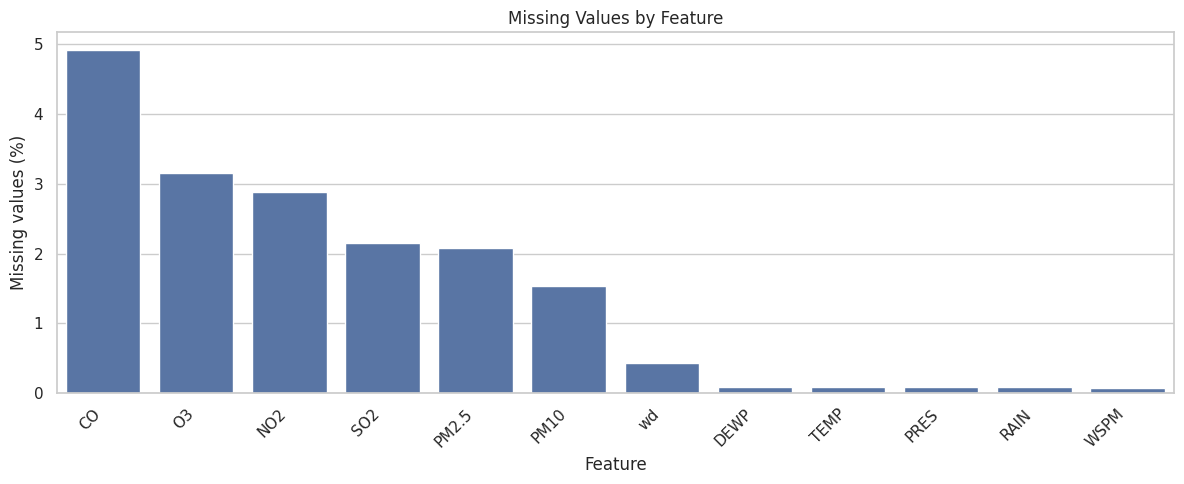

,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,datetime
station,,,,,,,,,,,,,,,,,
Aotizhongxin,0.0,0.0,0.0,0.0,2.64,2.05,2.67,2.92,5.07,4.90,0.06,0.06,0.06,0.06,0.23,0.04,0.0
Changping,0.0,0.0,0.0,0.0,2.21,1.66,1.79,1.90,4.34,1.72,0.15,0.14,0.15,0.15,0.40,0.12,0.0
Dingling,0.0,0.0,0.0,0.0,2.22,1.87,2.08,3.52,5.74,3.46,0.15,0.14,0.15,0.15,0.40,0.12,0.0
Dongsi,0.0,0.0,0.0,0.0,2.14,1.58,1.89,4.57,9.12,1.89,0.06,0.06,0.06,0.06,0.22,0.04,0.0
Guanyuan,0.0,0.0,0.0,0.0,1.76,1.22,1.35,1.88,5.00,3.35,0.06,0.06,0.06,0.06,0.23,0.04,0.0
Gucheng,0.0,0.0,0.0,0.0,1.84,1.09,1.45,1.91,4.00,2.08,0.15,0.14,0.15,0.12,0.45,0.12,0.0
Huairou,0.0,0.0,0.0,0.0,2.72,2.22,2.79,4.67,4.06,3.28,0.15,0.15,0.15,0.16,0.86,0.14,0.0
Nongzhanguan,0.0,0.0,0.0,0.0,1.79,1.25,1.27,1.97,3.44,1.44,0.06,0.06,0.06,0.06,0.22,0.04,0.0
Shunyi,0.0,0.0,0.0,0.0,2.60,1.56,3.70,3.89,6.21,4.25,0.15,0.15,0.15,0.15,1.38,0.13,0.0


In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": air_df.isna().sum(),
    "Missing Percentage": air_df.isna().mean() * 100,
}).sort_values("Missing Percentage", ascending=False)
display(missing_summary.round(2))

missing_features = missing_summary[missing_summary["Missing Count"] > 0]
if not missing_features.empty:
    plt.figure(figsize=(12, 5))
    sns.barplot(data=missing_features.reset_index(names="Feature"), x="Feature", y="Missing Percentage")
    plt.title("Missing Values by Feature")
    plt.ylabel("Missing values (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

missing_by_station = air_df.groupby("station").apply(
    lambda g: g.isna().mean() * 100, include_groups=False
)
display(missing_by_station.round(2))

## 6. Exploratory data analysis (EDA)

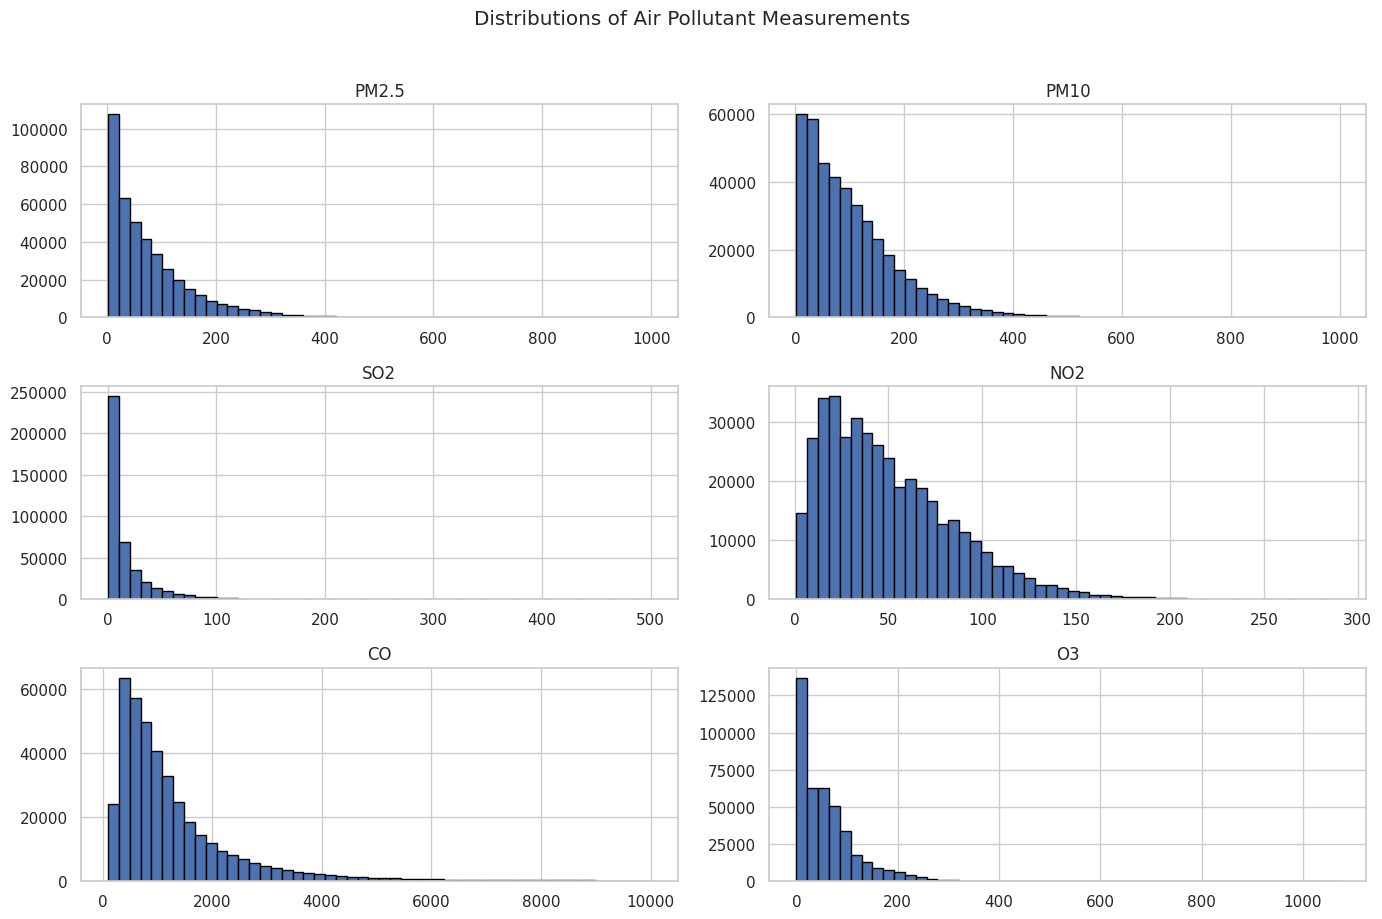

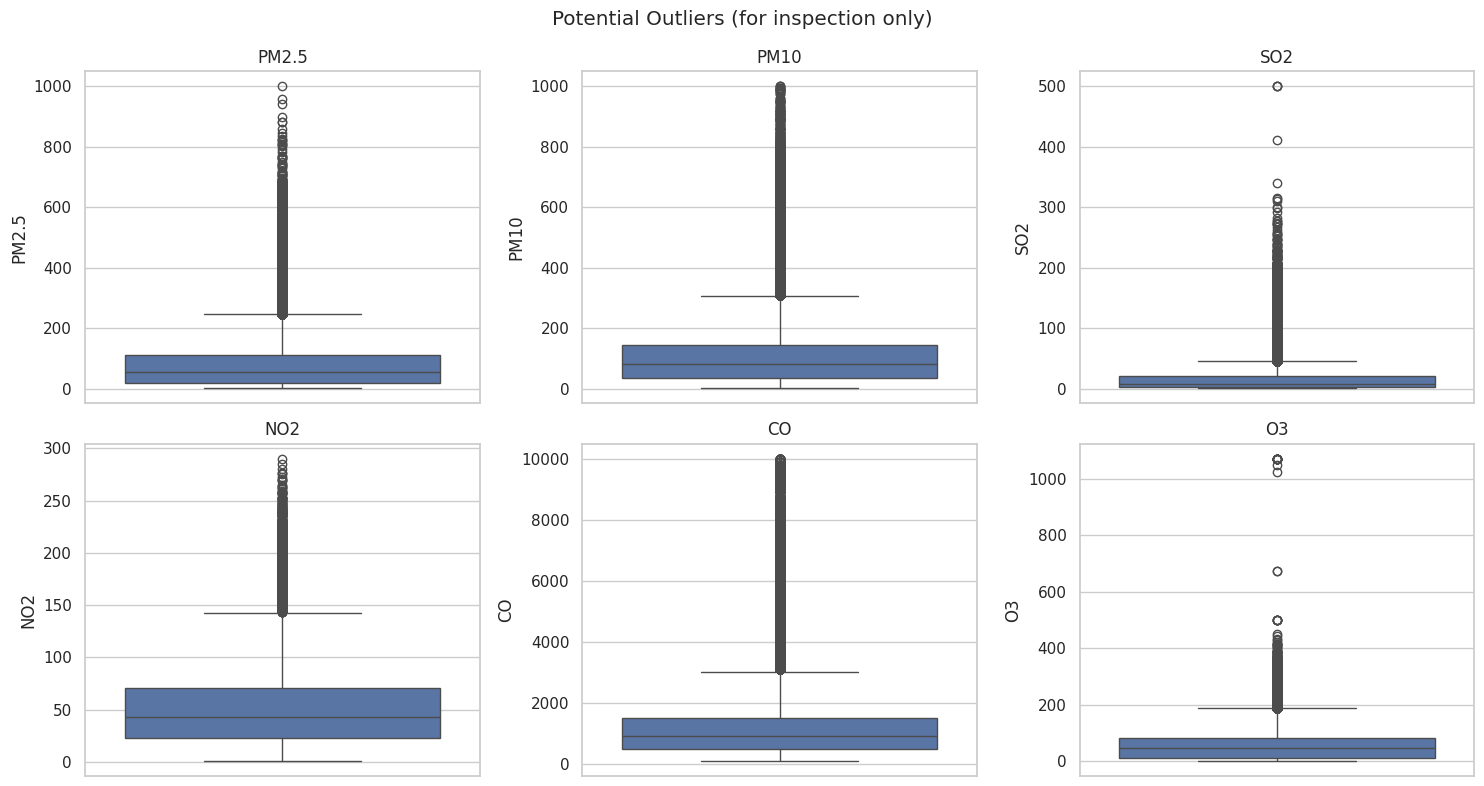

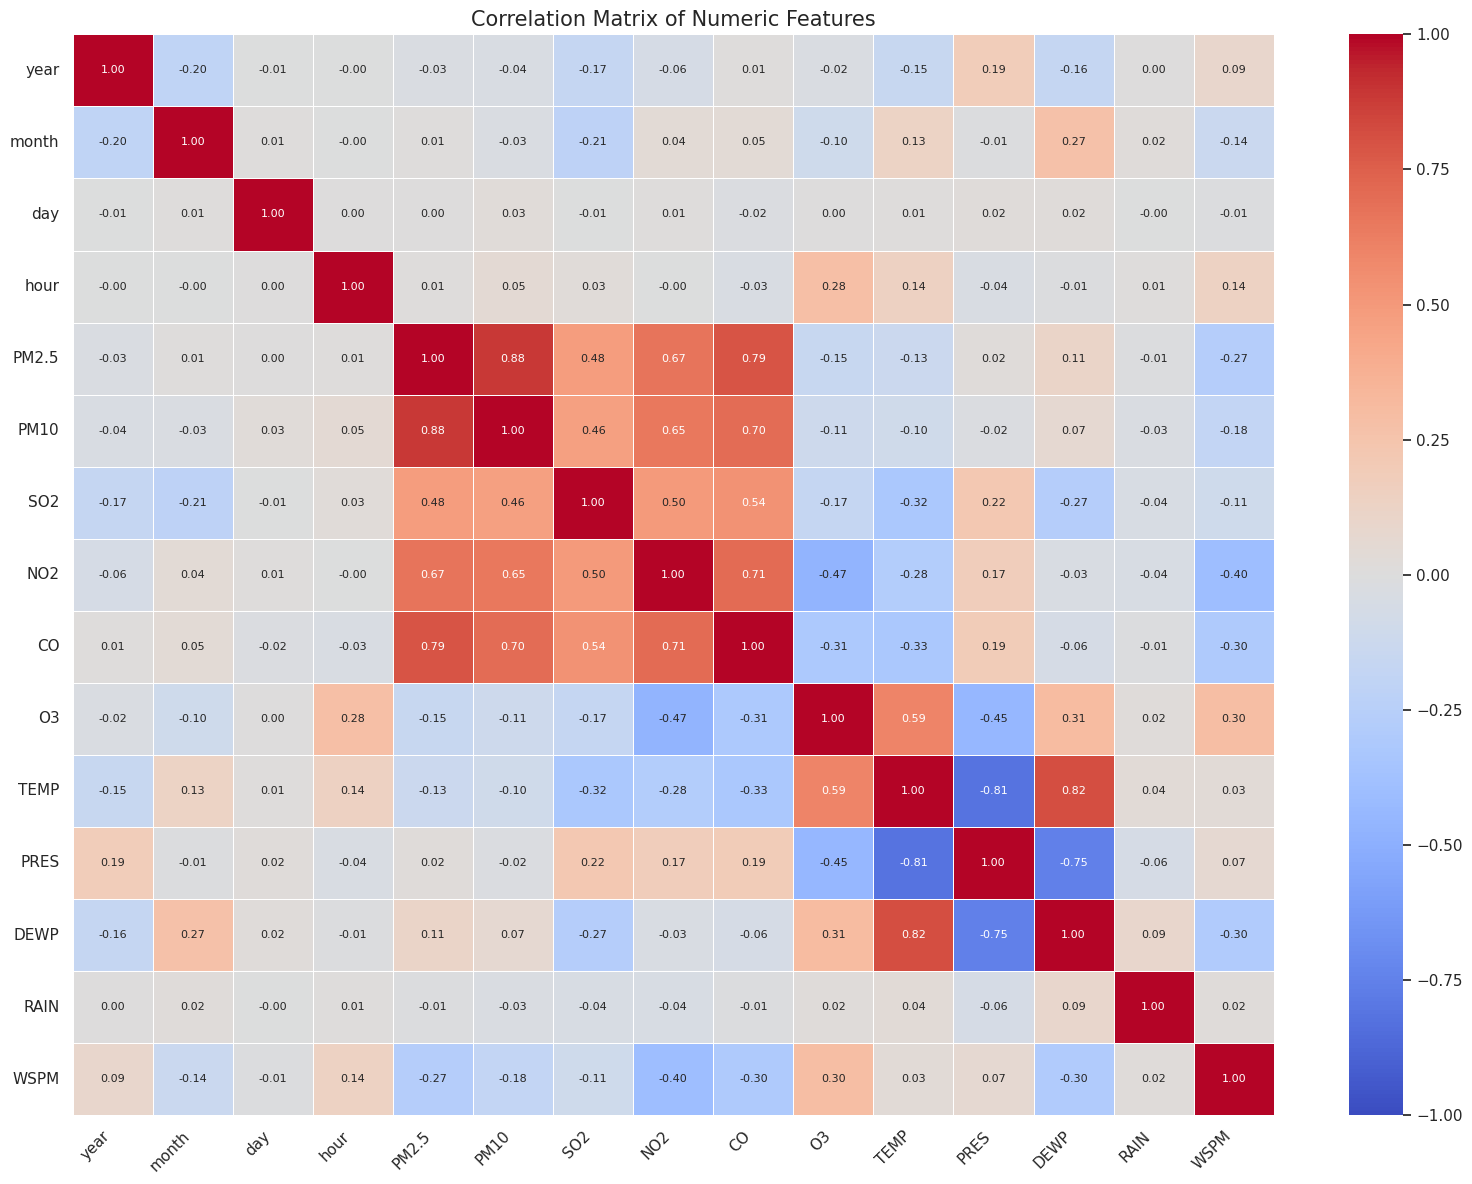

Correlation with PM2.5:


,correlation
PM2.5,1.000
PM10,0.884
CO,0.790
NO2,0.667
SO2,0.482
DEWP,0.115
PRES,0.019
hour,0.012
month,0.010
day,0.003


In [ ]:
pollutants = [
    c for c in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
    if c in air_df.columns
]

# 1. Pollutant distributions
if pollutants:
    air_df[pollutants].hist(
        figsize=(14, 9),
        bins=50,
        edgecolor="black"
    )

    plt.suptitle(
        "Distributions of Air Pollutant Measurements",
        y=1.02
    )
    plt.tight_layout()
    plt.show()

    # 2. Boxplots for outlier inspection
    fig, axes = plt.subplots(2, 3, figsize=(15, 8))

    for ax, col in zip(axes.flat, pollutants):
        sns.boxplot(y=air_df[col], ax=ax)
        ax.set_title(col)

    for ax in axes.flat[len(pollutants):]:
        ax.remove()

    plt.suptitle("Potential Outliers (for inspection only)")
    plt.tight_layout()
    plt.show()

# 3. Correlation matrix with values in each cell
numeric_df = air_df.select_dtypes(include=np.number)
corr_matrix = numeric_df.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    corr_matrix,
    annot=True,              # Show values in each cell
    fmt=".2f",               # Two decimal places
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 8}
)

plt.title("Correlation Matrix of Numeric Features", fontsize=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Features correlated with PM2.5
if "PM2.5" in numeric_df.columns:
    print("Correlation with PM2.5:")

    display(
        corr_matrix["PM2.5"]
        .sort_values(ascending=False)
        .to_frame("correlation")
        .round(3)
    )

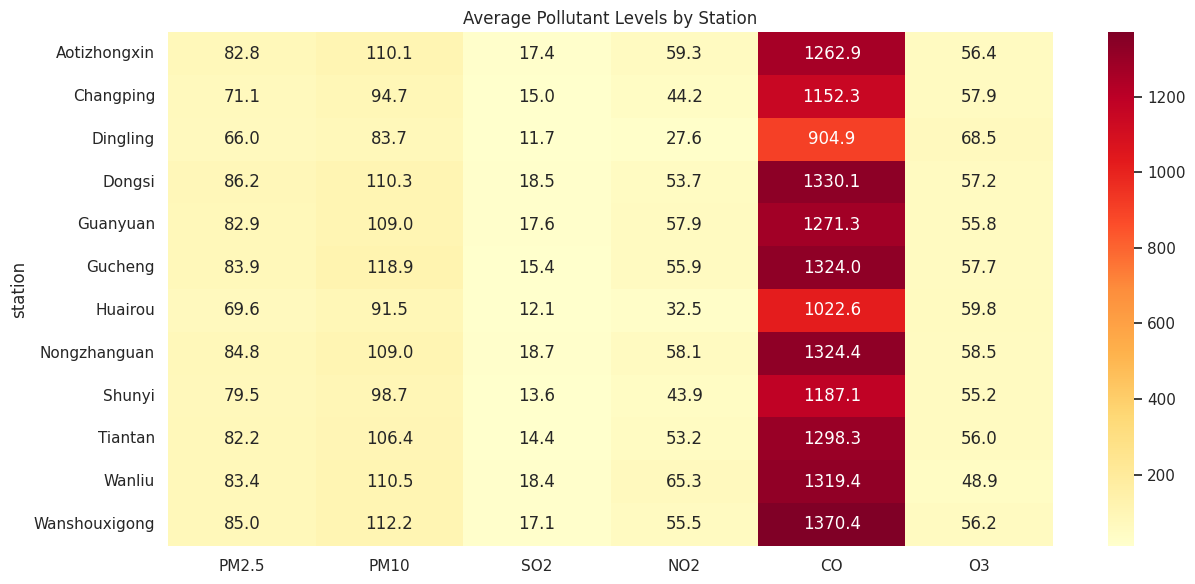

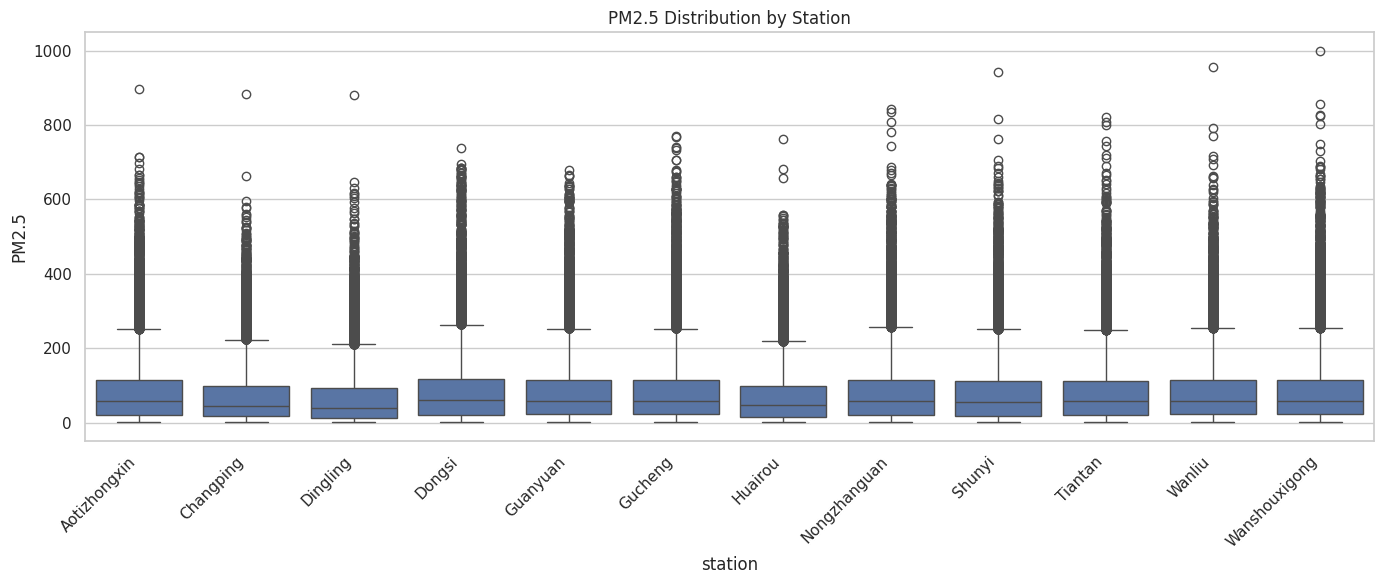

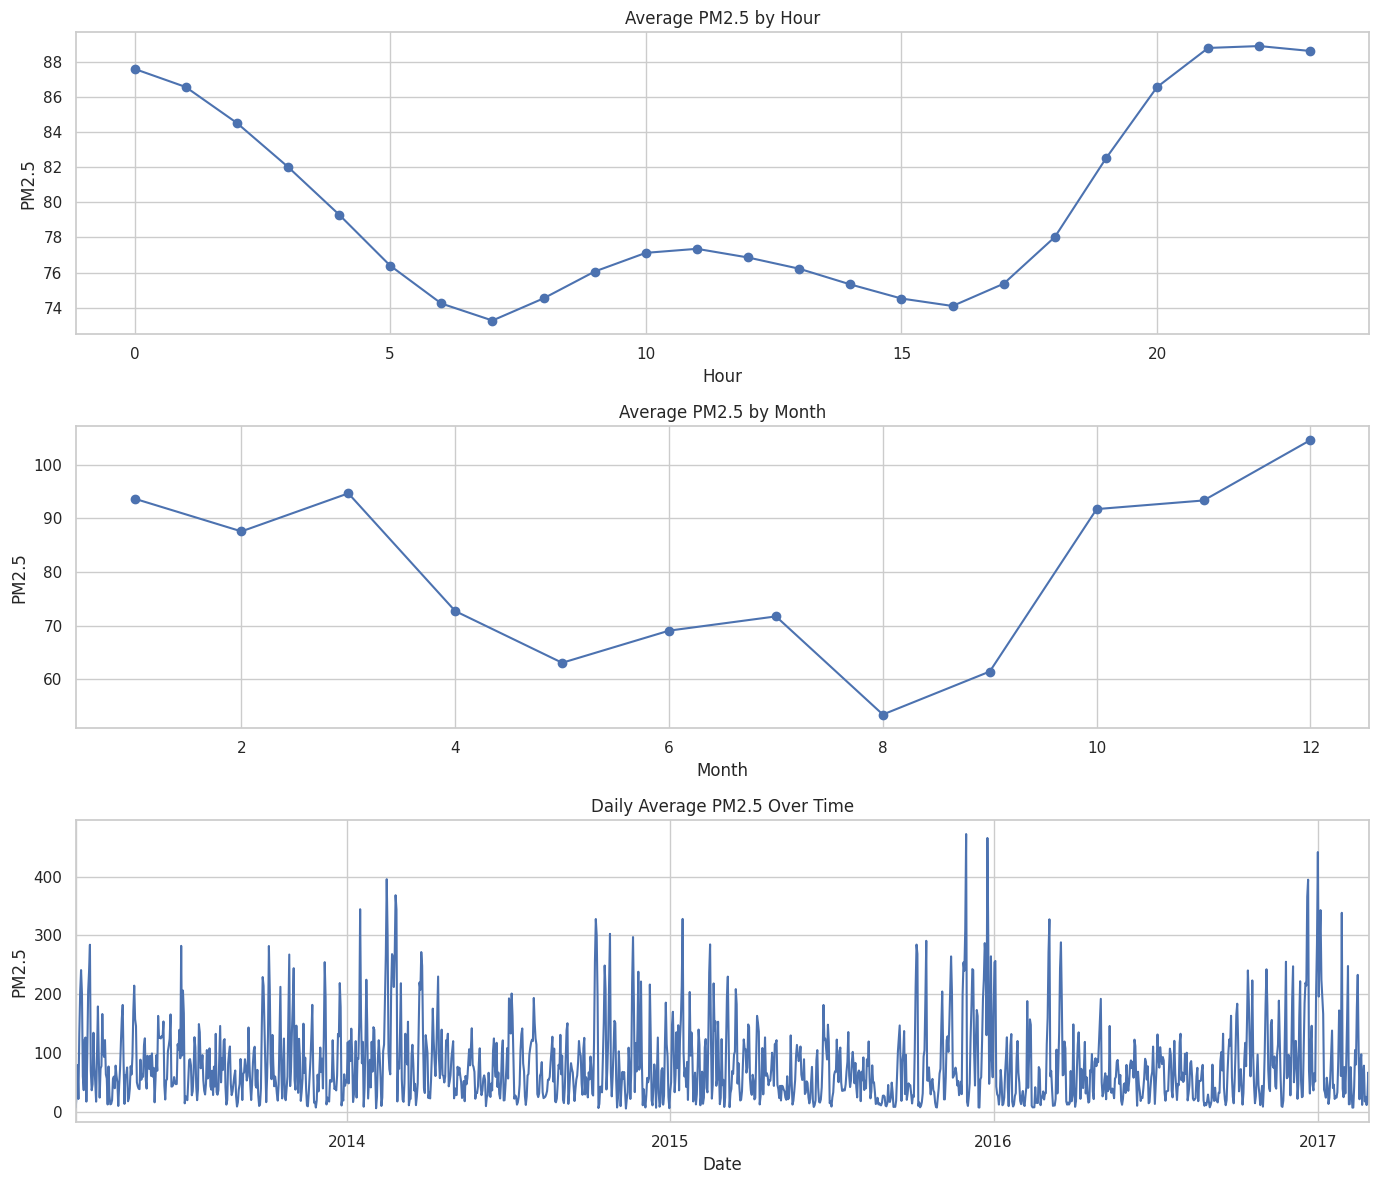

In [ ]:
# Station-level pollutant averages
if pollutants:
    station_means = air_df.groupby("station")[pollutants].mean()
    plt.figure(figsize=(13, 6))
    sns.heatmap(station_means, cmap="YlOrRd", annot=True, fmt=".1f")
    plt.title("Average Pollutant Levels by Station")
    plt.tight_layout()
    plt.show()

if "PM2.5" in air_df.columns:
    plt.figure(figsize=(14, 6))
    sns.boxplot(data=air_df, x="station", y="PM2.5")
    plt.title("PM2.5 Distribution by Station")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    hourly_pm25 = air_df.groupby("hour")["PM2.5"].mean()
    monthly_pm25 = air_df.groupby("month")["PM2.5"].mean().reindex(range(1, 13))
    daily_pm25 = air_df.groupby(air_df["datetime"].dt.floor("D"))["PM2.5"].mean()

    fig, axes = plt.subplots(3, 1, figsize=(14, 12))
    hourly_pm25.plot(ax=axes[0], marker="o")
    axes[0].set(title="Average PM2.5 by Hour", xlabel="Hour", ylabel="PM2.5")
    monthly_pm25.plot(ax=axes[1], marker="o")
    axes[1].set(title="Average PM2.5 by Month", xlabel="Month", ylabel="PM2.5")
    daily_pm25.plot(ax=axes[2])
    axes[2].set(title="Daily Average PM2.5 Over Time", xlabel="Date", ylabel="PM2.5")
    plt.tight_layout()
    plt.show()

## 7. Outlier inspection (do not automatically remove)

The IQR rule identifies values that are statistically unusual, not necessarily incorrect. We also count values at or above 999 for review. The notebook does not drop, cap, or replace these values automatically; first confirm whether any are invalid codes for this dataset.

In [ ]:
outlier_pollutants = [c for c in ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"] if c in air_df.columns]
outlier_rows = []
print("Counts at or above 999 (review these values; do not assume they are errors):")
for col in outlier_pollutants:
    print(f"{col}: {(air_df[col] >= 999).sum()}")
    values = air_df[col].dropna()
    if values.empty:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_outliers = ((values < lower) | (values > upper)).sum()
    outlier_rows.append({
        "Feature": col,
        "IQR Lower Bound": lower,
        "IQR Upper Bound": upper,
        "Potential Outliers": int(n_outliers),
        "Outlier Percentage": 100 * n_outliers / len(values),
    })
display(pd.DataFrame(outlier_rows).round(3))
print("\nPolicy: preserve plausible extreme pollution readings. Only correct/remove values after validating them against the dataset documentation or source records.")

Counts at or above 999 (review these values; do not assume they are errors):
PM2.5: 1
PM10: 3
SO2: 0
NO2: 0
CO: 184058
O3: 16


,Feature,IQR Lower Bound,IQR Upper Bound,Potential Outliers,Outlier Percentage
0,PM2.5,-116.5,247.5,19142,4.646
1,PM10,-127.5,308.5,14658,3.538
2,SO2,-22.5,45.5,35566,8.638
3,NO2,-49.0,143.0,7021,1.718
4,CO,-1000.0,3000.0,28054,7.012
5,O3,-95.5,188.5,16599,4.073



Policy: preserve plausible extreme pollution readings. Only correct/remove values after validating them against the dataset documentation or source records.


## 8. Create and verify the next-hour target

For each station, the target is the next available PM2.5 reading only when its timestamp is exactly one hour after the current row. The target is checked against the original station/time reading to catch alignment errors.

In [ ]:
target_df = air_df.sort_values(["station", "datetime"]).copy().reset_index(drop=True)
grouped = target_df.groupby("station", sort=False)
target_df["target_datetime"] = grouped["datetime"].shift(-1)
target_df["PM2.5_next_hour"] = grouped["PM2.5"].shift(-1)

is_exact_next_hour = (
    target_df["target_datetime"] - target_df["datetime"] == pd.Timedelta(hours=1)
)
target_df.loc[~is_exact_next_hour, "PM2.5_next_hour"] = np.nan

# Verify target values against the original PM2.5 record at target_datetime
future_values = air_df[["station", "datetime", "PM2.5"]].rename(
    columns={"datetime": "target_datetime", "PM2.5": "source_future_PM25"}
)
check_df = target_df.loc[target_df["PM2.5_next_hour"].notna(), [
    "station", "datetime", "target_datetime", "PM2.5_next_hour"
]].merge(future_values, on=["station", "target_datetime"], how="left", validate="many_to_one")
unmatched = int(check_df["source_future_PM25"].isna().sum())
mismatch = int((
    check_df["PM2.5_next_hour"].ne(check_df["source_future_PM25"])
    & check_df["source_future_PM25"].notna()
).sum())
print("Rows in source:", len(air_df))
print("Valid exact-next-hour targets:", int(target_df["PM2.5_next_hour"].notna().sum()))
print("Targets without matching source readings:", unmatched)
print("Target mismatches:", mismatch)
if unmatched or mismatch:
    raise ValueError("Target verification failed. Inspect the target alignment before proceeding.")
print("SUCCESS: every non-missing target matches the source reading at target_datetime.")
display(target_df[["station", "datetime", "PM2.5", "target_datetime", "PM2.5_next_hour"]].head(8))

Rows in source: 420768
Valid exact-next-hour targets: 412017
Targets without matching source readings: 0
Target mismatches: 0
SUCCESS: every non-missing target matches the source reading at target_datetime.


,station,datetime,PM2.5,target_datetime,PM2.5_next_hour
0,Aotizhongxin,2013-03-01 00:00:00,4.0,2013-03-01 01:00:00,8.0
1,Aotizhongxin,2013-03-01 01:00:00,8.0,2013-03-01 02:00:00,7.0
2,Aotizhongxin,2013-03-01 02:00:00,7.0,2013-03-01 03:00:00,6.0
3,Aotizhongxin,2013-03-01 03:00:00,6.0,2013-03-01 04:00:00,3.0
4,Aotizhongxin,2013-03-01 04:00:00,3.0,2013-03-01 05:00:00,5.0
5,Aotizhongxin,2013-03-01 05:00:00,5.0,2013-03-01 06:00:00,3.0
6,Aotizhongxin,2013-03-01 06:00:00,3.0,2013-03-01 07:00:00,3.0
7,Aotizhongxin,2013-03-01 07:00:00,3.0,2013-03-01 08:00:00,3.0


## 9. Create gap-aware lag and calendar features

Lag values are calculated within each station. A lag is retained only when the timestamp is exactly the expected number of hours earlier; this prevents a row shift across a time gap from being treated as a valid hourly lag. Missing lag values are kept for the training-only imputer to handle.

In [ ]:
feature_df = target_df.copy()
for lag in [1, 3, 6, 24]:
    feature_name = f"PM2.5_lag_{lag}"
    feature_df[feature_name] = feature_df.groupby("station", sort=False)["PM2.5"].shift(lag)
    previous_datetime = feature_df.groupby("station", sort=False)["datetime"].shift(lag)
    exact_lag = feature_df["datetime"] - previous_datetime == pd.Timedelta(hours=lag)
    feature_df.loc[~exact_lag, feature_name] = np.nan

feature_df["hour_sin"] = np.sin(2 * np.pi * feature_df["hour"] / 24)
feature_df["hour_cos"] = np.cos(2 * np.pi * feature_df["hour"] / 24)
feature_df["month_sin"] = np.sin(2 * np.pi * (feature_df["month"] - 1) / 12)
feature_df["month_cos"] = np.cos(2 * np.pi * (feature_df["month"] - 1) / 12)
feature_df["day_of_week"] = feature_df["datetime"].dt.dayofweek
feature_df["is_weekend"] = (feature_df["day_of_week"] >= 5).astype(int)

model_df = feature_df.dropna(subset=["PM2.5_next_hour", "target_datetime"]).copy()
model_df = model_df.sort_values(["target_datetime", "station"]).reset_index(drop=True)
print("Modeling dataset shape:", model_df.shape)
print("Target missing after filtering:", model_df["PM2.5_next_hour"].isna().sum())
lag_cols = [f"PM2.5_lag_{lag}" for lag in [1, 3, 6, 24]]
print("Lag missing-value counts:")
display(model_df[lag_cols].isna().sum().to_frame("missing_count"))
display(model_df[["station", "datetime", "PM2.5"] + lag_cols + ["target_datetime", "PM2.5_next_hour"]].head(10))

Modeling dataset shape: (412017, 30)
Target missing after filtering: 0
Lag missing-value counts:


,missing_count
PM2.5_lag_1,3845
PM2.5_lag_3,4636
PM2.5_lag_6,5262
PM2.5_lag_24,7126


,station,datetime,PM2.5,PM2.5_lag_1,PM2.5_lag_3,PM2.5_lag_6,PM2.5_lag_24,target_datetime,PM2.5_next_hour
0,Aotizhongxin,2013-03-01,4.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,8.0
1,Changping,2013-03-01,3.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,3.0
2,Dingling,2013-03-01,4.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,7.0
3,Dongsi,2013-03-01,9.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,4.0
4,Guanyuan,2013-03-01,4.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,4.0
5,Gucheng,2013-03-01,6.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,6.0
6,Huairou,2013-03-01,7.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,4.0
7,Nongzhanguan,2013-03-01,5.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,8.0
8,Shunyi,2013-03-01,3.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,12.0
9,Tiantan,2013-03-01,6.0,NaN,NaN,NaN,NaN,2013-03-01 01:00:00,6.0


## 10. Chronological train, validation, and test split

Splits use the timestamp of the value being predicted (`target_datetime`), not the feature timestamp. This ensures the target periods are ordered in time.

In [ ]:
train_end = pd.Timestamp("2016-01-01")
validation_end = pd.Timestamp("2016-09-01")

train_df = model_df[model_df["target_datetime"] < train_end].copy()
val_df = model_df[
    (model_df["target_datetime"] >= train_end)
    & (model_df["target_datetime"] < validation_end)
].copy()
test_df = model_df[model_df["target_datetime"] >= validation_end].copy()

splits = {
    "Train": train_df,
    "Validation": val_df,
    "Test": test_df,
}
for name, frame in splits.items():
    print(f"{name}: {frame.shape}; target period: {frame['target_datetime'].min()} to {frame['target_datetime'].max()}")

if min(len(train_df), len(val_df), len(test_df)) == 0:
    raise ValueError("One or more splits are empty. Check date boundaries and source data.")
assert train_df["target_datetime"].max() < val_df["target_datetime"].min()
assert val_df["target_datetime"].max() < test_df["target_datetime"].min()
print("Chronological split check passed.")

Train: (292138, 30); target period: 2013-03-01 01:00:00 to 2015-12-31 23:00:00
Validation: (68816, 30); target period: 2016-01-01 00:00:00 to 2016-08-31 23:00:00
Test: (51063, 30); target period: 2016-09-01 00:00:00 to 2017-02-28 23:00:00
Chronological split check passed.


## 11. Prepare features and fit preprocessing on training data only

`datetime`, `target_datetime`, and the target itself are excluded from model inputs. Numeric columns receive median imputation and standard scaling; categorical columns receive most-frequent imputation and one-hot encoding. Only the training partition is used to fit these transformations.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TARGET = "PM2.5_next_hour"
EXCLUDE_FROM_X = [TARGET, "target_datetime", "datetime"]

X_train = train_df.drop(columns=EXCLUDE_FROM_X)
y_train = train_df[TARGET].astype(float).copy()
X_val = val_df.drop(columns=EXCLUDE_FROM_X)
y_val = val_df[TARGET].astype(float).copy()
X_test = test_df.drop(columns=EXCLUDE_FROM_X)
y_test = test_df[TARGET].astype(float).copy()

numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Numeric feature count:", len(numeric_features))
print("Categorical features:", categorical_features)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
], remainder="drop")

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to float arrays and verify no NaN/inf values remain
X_train_processed = np.asarray(X_train_processed, dtype=np.float32)
X_val_processed = np.asarray(X_val_processed, dtype=np.float32)
X_test_processed = np.asarray(X_test_processed, dtype=np.float32)
for name, arr in [("Train", X_train_processed), ("Validation", X_val_processed), ("Test", X_test_processed)]:
    print(f"{name} processed shape: {arr.shape}; NaNs: {np.isnan(arr).sum()}; infinite values: {np.isinf(arr).sum()}")
    if not np.isfinite(arr).all():
        raise ValueError(f"Non-finite values found in processed {name} features.")
print("Target shapes:", y_train.shape, y_val.shape, y_test.shape)

Numeric feature count: 25
Categorical features: ['wd', 'station']
Train processed shape: (292138, 53); NaNs: 0; infinite values: 0
Validation processed shape: (68816, 53); NaNs: 0; infinite values: 0
Test processed shape: (51063, 53); NaNs: 0; infinite values: 0
Target shapes: (292138,) (68816,) (51063,)


## 12. Save model-ready data and preprocessing object

The engineered CSVs preserve timestamps and target values for analysis. The compressed NPZ files contain the transformed feature arrays and target vectors for model training. The fitted preprocessor is saved so the same transformations can be applied later.

In [ ]:
import joblib

# Save target-prepared and engineered datasets
model_df.to_csv(TARGET_PREPARED_PATH, index=False)
train_df.to_csv(DATA_DIR / "train_engineered.csv", index=False)
val_df.to_csv(DATA_DIR / "validation_engineered.csv", index=False)
test_df.to_csv(DATA_DIR / "test_engineered.csv", index=False)

# Save transformed matrices and target vectors
np.savez_compressed(DATA_DIR / "train_processed.npz", X=X_train_processed, y=y_train.to_numpy(dtype=np.float32))
np.savez_compressed(DATA_DIR / "validation_processed.npz", X=X_val_processed, y=y_val.to_numpy(dtype=np.float32))
np.savez_compressed(DATA_DIR / "test_processed.npz", X=X_test_processed, y=y_test.to_numpy(dtype=np.float32))
joblib.dump(preprocessor, DATA_DIR / "preprocessor.joblib")

# Save the feature column names in transformed order
try:
    transformed_feature_names = preprocessor.get_feature_names_out().tolist()
    pd.Series(transformed_feature_names, name="feature_name").to_csv(DATA_DIR / "processed_feature_names.csv", index=False)
except Exception as exc:
    print("Could not export transformed feature names:", exc)

print("Saved files to:", DATA_DIR)
for file in sorted(DATA_DIR.glob("*")):
    if file.is_file() and file.name in {
        "beijing_air_quality_target_prepared.csv", "train_engineered.csv",
        "validation_engineered.csv", "test_engineered.csv", "train_processed.npz",
        "validation_processed.npz", "test_processed.npz", "preprocessor.joblib",
        "processed_feature_names.csv"
    }:
        print(f"- {file.name}: {file.stat().st_size / (1024**2):.2f} MB")

Saved files to: /content/drive/MyDrive/DSA_B11/Majorproject/Dataset
- beijing_air_quality_target_prepared.csv: 86.81 MB
- preprocessor.joblib: 0.01 MB
- processed_feature_names.csv: 0.00 MB
- test_engineered.csv: 10.71 MB
- test_processed.npz: 1.86 MB
- train_engineered.csv: 61.77 MB
- train_processed.npz: 11.00 MB
- validation_engineered.csv: 14.32 MB
- validation_processed.npz: 2.47 MB


## 13. Load saved model-ready arrays and verify row alignment

The train, validation and test arrays were created from the engineered CSVs in the same chronological order. Before using them for feature selection or tuning, verify **row-by-row alignment**, not just matching row counts.

This section reuses saved artifacts. It does not repeat preprocessing or retrain the six benchmark models.

In [ ]:
# Load saved processed arrays, engineered rows, preprocessor and feature names.
import joblib
import gc
from pathlib import Path

train_data = np.load(DATA_DIR / "train_processed.npz")
val_data = np.load(DATA_DIR / "validation_processed.npz")
test_data = np.load(DATA_DIR / "test_processed.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_val, y_val = val_data["X"], val_data["y"]
X_test, y_test = test_data["X"], test_data["y"]

train_df = pd.read_csv(DATA_DIR / "train_engineered.csv", parse_dates=["datetime", "target_datetime"])
val_df = pd.read_csv(DATA_DIR / "validation_engineered.csv", parse_dates=["datetime", "target_datetime"])
test_df = pd.read_csv(DATA_DIR / "test_engineered.csv", parse_dates=["datetime", "target_datetime"])

preprocessor = joblib.load(DATA_DIR / "preprocessor.joblib")
processed_feature_names = pd.read_csv(
    DATA_DIR / "processed_feature_names.csv"
).iloc[:, 0].astype(str).tolist()

TARGET = "PM2.5_next_hour"
EXCLUDE_FROM_X = [TARGET, "target_datetime", "datetime"]

print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "| y_test: ", y_test.shape)
print("Processed feature names:", len(processed_feature_names))
print("Engineered CSV rows:", len(train_df), len(val_df), len(test_df))


X_train: (292138, 53) | y_train: (292138,)
X_val:   (68816, 53) | y_val:   (68816,)
X_test:  (51063, 53) | y_test:  (51063,)
Processed feature names: 53
Engineered CSV rows: 292138 68816 51063


In [ ]:
# Verify target alignment and processed-feature alignment in small batches.
# Batching avoids creating a second full-size transformed matrix in RAM.

def verify_split_alignment(frame, X_saved, y_saved, split_name, batch_size=20000):
    y_from_csv = frame[TARGET].to_numpy(dtype=np.float32)

    if len(frame) != len(X_saved) or len(frame) != len(y_saved):
        raise ValueError(f"{split_name}: row counts do not match.")

    if not np.allclose(y_from_csv, y_saved, rtol=0, atol=1e-6, equal_nan=True):
        raise ValueError(f"{split_name}: target row ordering/value mismatch.")

    X_raw = frame.drop(columns=EXCLUDE_FROM_X)
    max_abs_diff = 0.0

    for start in range(0, len(frame), batch_size):
        stop = min(start + batch_size, len(frame))
        transformed = preprocessor.transform(X_raw.iloc[start:stop])
        transformed = np.asarray(transformed, dtype=np.float32)

        if transformed.shape[1] != X_saved.shape[1]:
            raise ValueError(f"{split_name}: transformed feature count mismatch.")

        batch_diff = float(np.max(np.abs(transformed - X_saved[start:stop])))
        max_abs_diff = max(max_abs_diff, batch_diff)

        if not np.allclose(transformed, X_saved[start:stop], rtol=1e-5, atol=1e-5):
            raise ValueError(f"{split_name}: processed feature row mismatch near row {start}.")

    print(f"{split_name}: alignment PASSED | max feature difference={max_abs_diff:.8g}")

for name, frame, X, y in [
    ("Train", train_df, X_train, y_train),
    ("Validation", val_df, X_val, y_val),
    ("Test", test_df, X_test, y_test),
]:
    verify_split_alignment(frame, X, y, name)

assert X_train.shape[1] == len(processed_feature_names)
assert np.isfinite(X_train).all() and np.isfinite(X_val).all() and np.isfinite(X_test).all()
assert train_df["target_datetime"].max() < val_df["target_datetime"].min()
assert val_df["target_datetime"].max() < test_df["target_datetime"].min()

print("\nAll row-alignment, finite-value and chronological checks passed.")


Train: alignment PASSED | max feature difference=0
Validation: alignment PASSED | max feature difference=0
Test: alignment PASSED | max feature difference=0

All row-alignment, finite-value and chronological checks passed.


## 14. Reproduce the six-model baseline comparison

These are the previously completed validation results. **Do not retrain all six models.** Random Forest was the best initial model by validation RMSE. Training time is omitted because timings varied between runtime sessions and are hardware-dependent.

In [ ]:
baseline_results = pd.DataFrame([
    {"Model": "Random Forest", "MAE": 8.6702, "RMSE": 17.3976, "R2": 0.9267},
    {"Model": "Extra Trees", "MAE": 8.7289, "RMSE": 17.5741, "R2": 0.9252},
    {"Model": "LightGBM", "MAE": 8.7930, "RMSE": 17.7262, "R2": 0.9239},
    {"Model": "CatBoost", "MAE": 8.8108, "RMSE": 17.9997, "R2": 0.9215},
    {"Model": "HistGradientBoosting", "MAE": 8.7882, "RMSE": 18.1513, "R2": 0.9202},
    {"Model": "XGBoost", "MAE": 8.9328, "RMSE": 18.2892, "R2": 0.9190},
]).sort_values("RMSE").reset_index(drop=True)

display(baseline_results.style.format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "R2": "{:.4f}"}))
print("Best initial validation model:", baseline_results.iloc[0]["Model"])


,Model,MAE,RMSE,R2
0,Random Forest,8.6702,17.3976,0.9267
1,Extra Trees,8.7289,17.5741,0.9252
2,LightGBM,8.7930,17.7262,0.9239
3,CatBoost,8.8108,17.9997,0.9215
4,HistGradientBoosting,8.7882,18.1513,0.9202
5,XGBoost,8.9328,18.2892,0.9190


Best initial validation model: Random Forest


**Existing Random Forest configuration:** `n_estimators=100`, `max_depth=30`, `max_features=0.7`, `min_samples_leaf=3`, `min_samples_split=9`, `random_state=42`. This was selected in the previous tuning work and reproduced the reported validation result. The earlier 30-fit RandomizedSearchCV took about 93 minutes, so it is deliberately not repeated.

## 15. Random Forest feature importance

Load **only the Random Forest model**, extract its importance array, then release the model from memory. This avoids keeping several large model objects in RAM.

In [ ]:
rf_path = DATA_DIR / "random_forest_model.joblib"
if not rf_path.exists():
    raise FileNotFoundError(f"Saved Random Forest model not found: {rf_path}")

rf_model = joblib.load(rf_path)

rf_importance = pd.DataFrame({
    "Feature": processed_feature_names,
    "Importance": np.asarray(rf_model.feature_importances_, dtype=float)
}).sort_values("Importance", ascending=False).reset_index(drop=True)

# Retain only the small importance table; release the fitted model.
del rf_model
gc.collect()

print("Number of processed features:", len(rf_importance))
print("Importance sum:", rf_importance["Importance"].sum())
display(rf_importance.head(20).round(6))

rf_importance.to_csv(DATA_DIR / "random_forest_feature_importance.csv", index=False)


Number of processed features: 53
Importance sum: 0.9999999999999999


,Feature,Importance
0,numeric__PM2.5,0.672889
1,numeric__PM2.5_lag_1,0.229646
2,numeric__PM10,0.044382
3,numeric__PM2.5_lag_3,0.016593
4,numeric__WSPM,0.004273
5,numeric__PM2.5_lag_6,0.003547
6,numeric__DEWP,0.002967
7,numeric__PM2.5_lag_24,0.002574
8,numeric__CO,0.002442
9,numeric__NO2,0.002318


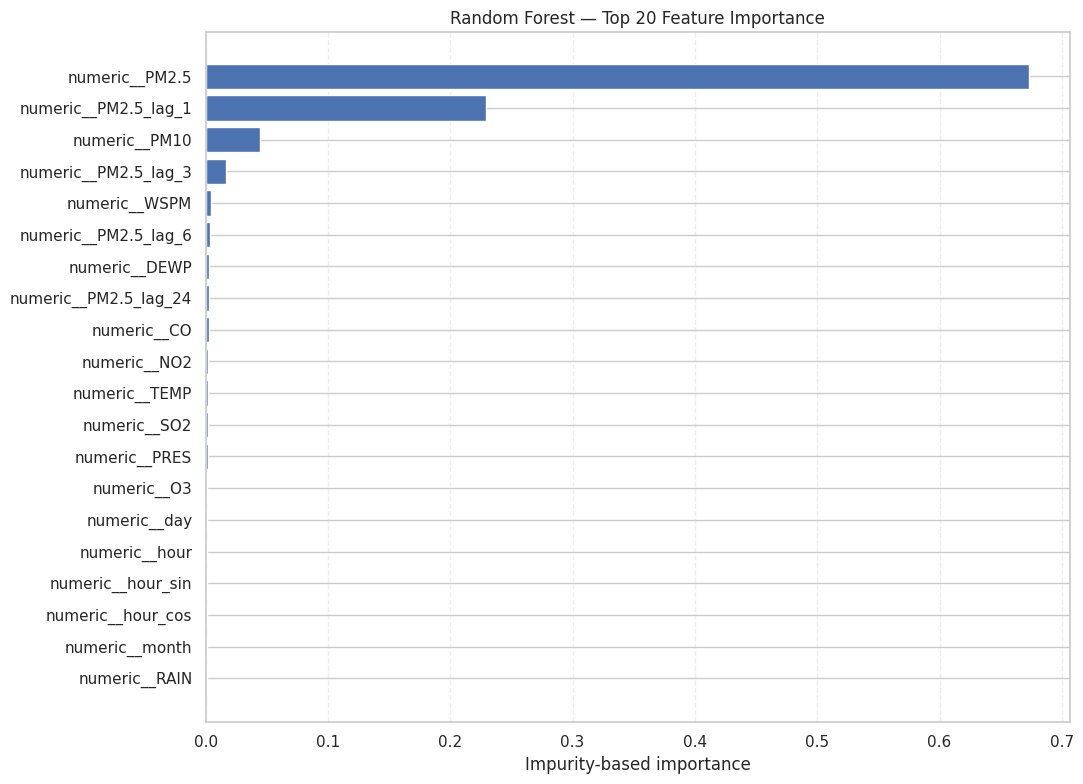

In [ ]:
top20_rf = rf_importance.head(20).sort_values("Importance")

plt.figure(figsize=(11, 8))
plt.barh(top20_rf["Feature"], top20_rf["Importance"])
plt.xlabel("Impurity-based importance")
plt.title("Random Forest — Top 20 Feature Importance")
plt.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()


## 16. Compare built-in importance across models (one model loaded at a time)

LightGBM is represented using **gain** importance rather than split counts. Other models expose their own native importance definitions. Scores are normalized to percentages within each model for easier display, but the underlying definitions still differ and should not be interpreted as perfectly equivalent.

HistGradientBoosting does not expose `feature_importances_`; it is intentionally omitted from this built-in comparison.

In [ ]:
# Reuse Random Forest importance already extracted; load other models one by one.
model_files = {
    "Extra Trees": "extra_trees_model.joblib",
    "LightGBM": "lightgbm_model.joblib",
    "XGBoost": "xgboost_model.joblib",
    "CatBoost": "catboost_model.joblib",
}

importance_columns = {
    "Random Forest": 100 * rf_importance.set_index("Feature")["Importance"].reindex(processed_feature_names).to_numpy()
}

for model_name, filename in model_files.items():
    path = DATA_DIR / filename
    if not path.exists():
        print(f"Skipping missing model: {filename}")
        continue

    print(f"Extracting {model_name}...", flush=True)
    model = joblib.load(path)

    if model_name == "LightGBM" and hasattr(model, "booster_"):
        raw_importance = model.booster_.feature_importance(importance_type="gain")
    elif hasattr(model, "feature_importances_"):
        raw_importance = np.asarray(model.feature_importances_, dtype=float)
    else:
        print(f"No native importance available for {model_name}.")
        del model
        gc.collect()
        continue

    raw_importance = np.asarray(raw_importance, dtype=float)
    if len(raw_importance) == len(processed_feature_names) and raw_importance.sum() > 0:
        importance_columns[model_name] = 100 * raw_importance / raw_importance.sum()
    else:
        print(f"Feature count or importance sum issue for {model_name}; skipped.")

    del model, raw_importance
    gc.collect()

importance_comparison = pd.DataFrame(importance_columns, index=processed_feature_names)
display(importance_comparison.loc[rf_importance.head(20)["Feature"]].round(3))
importance_comparison.to_csv(DATA_DIR / "normalized_native_feature_importance.csv")


Skipping missing model: extra_trees_model.joblib
Extracting LightGBM...
Extracting XGBoost...
Extracting CatBoost...


,Random Forest,LightGBM,XGBoost,CatBoost
numeric__PM2.5,67.289,82.291,60.516,65.267
numeric__PM2.5_lag_1,22.965,11.396,21.218,8.784
numeric__PM10,4.438,3.506,3.877,5.519
numeric__PM2.5_lag_3,1.659,0.275,0.557,1.077
numeric__WSPM,0.427,0.369,0.616,2.783
numeric__PM2.5_lag_6,0.355,0.119,0.272,0.816
numeric__DEWP,0.297,0.258,0.432,2.641
numeric__PM2.5_lag_24,0.257,0.149,0.303,1.198
numeric__CO,0.244,0.284,0.607,1.277
numeric__NO2,0.232,0.125,0.362,1.060


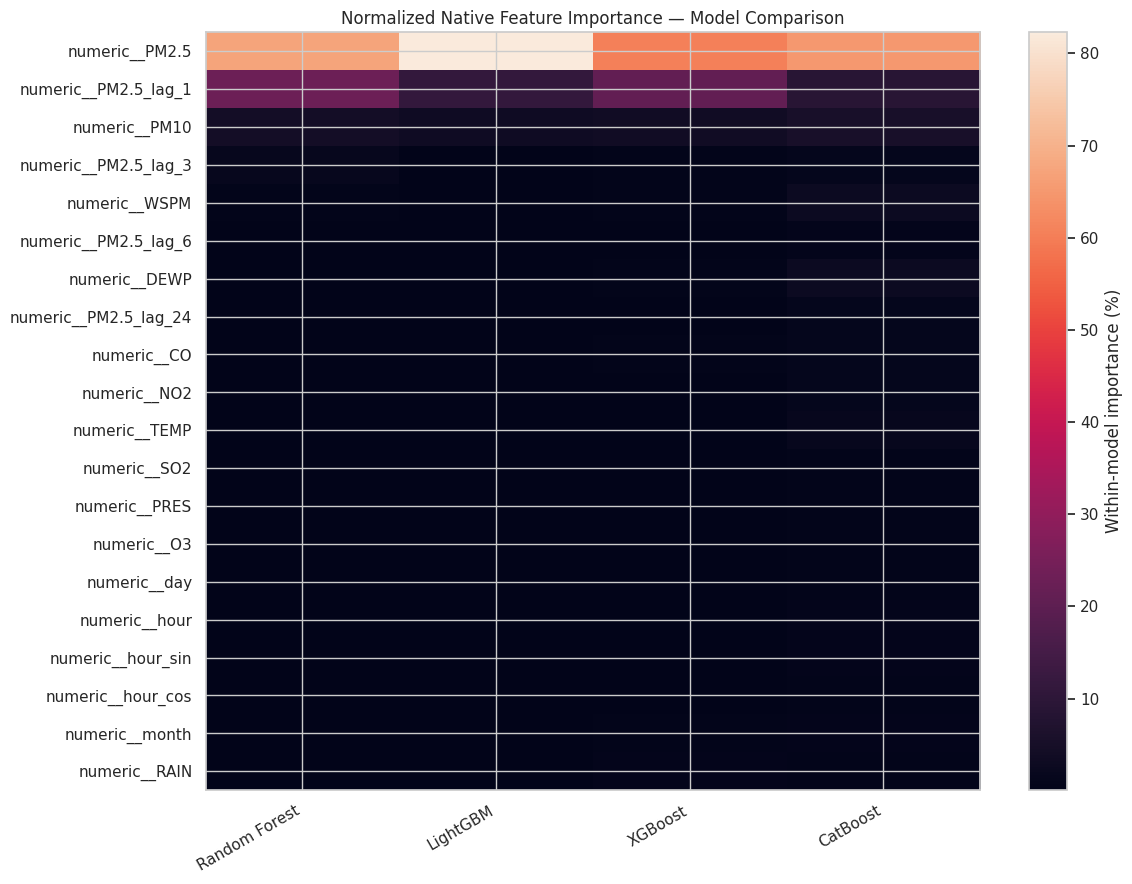

In [ ]:
# Heatmap of normalized native importance (top 20 Random Forest-ranked features)
comparison_top20 = importance_comparison.loc[rf_importance.head(20)["Feature"]]

plt.figure(figsize=(12, 9))
plt.imshow(comparison_top20.values, aspect="auto")
plt.colorbar(label="Within-model importance (%)")
plt.xticks(range(len(comparison_top20.columns)), comparison_top20.columns, rotation=30, ha="right")
plt.yticks(range(len(comparison_top20.index)), comparison_top20.index)
plt.title("Normalized Native Feature Importance — Model Comparison")
plt.tight_layout()
plt.show()


## 17. Permutation importance (Random Forest only)

Permutation importance measures how much validation error increases when one feature is shuffled. The earlier full-validation Random Forest analysis (5 repeats) has already been completed. To make this notebook safer to rerun, the optional reproducible cell below uses a fixed **5,000-row validation sample and 2 repeats**. It is not necessary to calculate permutation importance for every model.

Correlated predictors can substitute for one another, so permutation importance may understate the individual contribution of correlated features.

In [ ]:
# OPTIONAL: run this cell if you want to regenerate a lighter permutation-importance estimate.
# It loads only Random Forest and uses a sample to limit memory/time.

from sklearn.inspection import permutation_importance

rf_model = joblib.load(DATA_DIR / "random_forest_model.joblib")

rng = np.random.default_rng(RANDOM_STATE)
perm_n = min(5000, len(y_val))
perm_idx = rng.choice(len(y_val), size=perm_n, replace=False)

perm_result = permutation_importance(
    rf_model,
    X_val[perm_idx],
    y_val[perm_idx],
    scoring="neg_root_mean_squared_error",
    n_repeats=2,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

rf_perm_importance = pd.DataFrame({
    "Feature": processed_feature_names,
    "Importance_Mean": perm_result.importances_mean,
    "Importance_Std": perm_result.importances_std,
}).sort_values("Importance_Mean", ascending=False).reset_index(drop=True)

display(rf_perm_importance.head(20).round(5))
rf_perm_importance.to_csv(DATA_DIR / "random_forest_permutation_importance_sampled.csv", index=False)

del rf_model, perm_result
gc.collect()


,Feature,Importance_Mean,Importance_Std
0,numeric__PM2.5,50.59606,0.23512
1,numeric__PM10,6.75879,0.23104
2,numeric__PM2.5_lag_1,3.45150,0.11609
3,numeric__WSPM,1.34962,0.15038
4,numeric__O3,0.53549,0.04589
5,numeric__PM2.5_lag_3,0.43468,0.14689
6,numeric__DEWP,0.35284,0.06996
7,numeric__PM2.5_lag_6,0.25773,0.05904
8,numeric__NO2,0.24811,0.01044
9,numeric__CO,0.17762,0.05812


6467

## 18. Correlation review for feature selection

Correlation is a diagnostic, not an automatic deletion rule. We inspect the original numeric engineered features in the training partition only. Highly correlated features may be redundant, but tree models can still use them differently.

In [ ]:
numeric_train_cols = train_df.select_dtypes(include=np.number).columns.tolist()
numeric_train_cols = [c for c in numeric_train_cols if c not in [TARGET]]

corr_train = train_df[numeric_train_cols].corr(method="spearman")
upper = corr_train.abs().where(np.triu(np.ones(corr_train.shape), k=1).astype(bool))

high_corr_pairs = (
    upper.stack()
    .rename("Absolute_Spearman_Correlation")
    .reset_index()
    .rename(columns={"level_0": "Feature_1", "level_1": "Feature_2"})
    .query("Absolute_Spearman_Correlation >= 0.90")
    .sort_values("Absolute_Spearman_Correlation", ascending=False)
)

print("Highly correlated numeric feature pairs (|Spearman rho| >= 0.90):")
display(high_corr_pairs.round(3))
high_corr_pairs.to_csv(DATA_DIR / "high_correlation_pairs_train.csv", index=False)


Highly correlated numeric feature pairs (|Spearman rho| >= 0.90):


,Feature_1,Feature_2,Absolute_Spearman_Correlation
100,PM2.5,PM2.5_lag_1,0.964
255,PM2.5_lag_1,PM2.5_lag_3,0.922


## 19. Feature selection experiment

We will test whether a smaller feature set can maintain or improve validation performance. The ranking comes from Random Forest importance calculated on the training-fitted model. We compare **all 53**, **top 40**, **top 30**, and **top 20** features using the same LightGBM configuration.

This is an empirical feature-selection experiment: do not remove features solely because their importance is small. The validation set is used for model/feature-set selection; the test set remains untouched.

In [ ]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import time

# Feature ranking based on Random Forest impurity importance.
ranked_features = rf_importance["Feature"].tolist()
feature_to_index = {name: i for i, name in enumerate(processed_feature_names)}

feature_sets = {
    "All 53 features": processed_feature_names,
    "Top 40": ranked_features[:40],
    "Top 30": ranked_features[:30],
    "Top 20": ranked_features[:20],
}

selection_config = dict(
    n_estimators=700,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    random_state=RANDOM_STATE,
    n_jobs=2,
    verbosity=-1,
)

selection_rows = []

for set_name, feature_list in feature_sets.items():
    idx = np.array([feature_to_index[f] for f in feature_list], dtype=int)
    print(f"Training LightGBM with {set_name} ({len(idx)} features)...", flush=True)

    candidate = LGBMRegressor(**selection_config)
    start = time.time()
    candidate.fit(X_train[:, idx], y_train)
    pred = candidate.predict(X_val[:, idx])

    selection_rows.append({
        "Feature_Set": set_name,
        "Number_of_Features": len(idx),
        "MAE": mean_absolute_error(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "R2": r2_score(y_val, pred),
        "Training_Time_Seconds": time.time() - start,
    })

    del candidate, pred
    gc.collect()

feature_selection_results = pd.DataFrame(selection_rows).sort_values("RMSE").reset_index(drop=True)
display(feature_selection_results.round(4))
feature_selection_results.to_csv(DATA_DIR / "feature_selection_results.csv", index=False)

best_set_name = feature_selection_results.iloc[0]["Feature_Set"]
selected_feature_names = feature_sets[best_set_name]
selected_feature_indices = np.array([feature_to_index[f] for f in selected_feature_names], dtype=int)

print("Selected feature set:", best_set_name)
print("Selected feature count:", len(selected_feature_names))
pd.Series(selected_feature_names, name="selected_feature").to_csv(
    DATA_DIR / "selected_feature_names.csv", index=False
)


Training LightGBM with All 53 features (53 features)...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Training LightGBM with Top 40 (40 features)...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Training LightGBM with Top 30 (30 features)...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Training LightGBM with Top 20 (20 features)...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Feature_Set,Number_of_Features,MAE,RMSE,R2,Training_Time_Seconds
0,All 53 features,53,8.7752,17.6768,0.9243,34.2973
1,Top 30,30,8.7926,17.7457,0.9237,34.5698
2,Top 20,20,8.9154,17.8687,0.9226,26.7162
3,Top 40,40,8.7943,17.8749,0.9226,34.0823


Selected feature set: All 53 features
Selected feature count: 53


## 20. Lightweight LightGBM hyperparameter tuning

Random Forest already has a previously tuned configuration and remains our strongest initial validation model. To avoid repeating the expensive RandomizedSearchCV experiment, we run a small, controlled LightGBM comparison on the feature set selected above.

The candidates are trained on the full training partition and compared on the chronological validation partition. This is a holdout tuning procedure, not cross-validation. The test set is not used.

In [ ]:
lgbm_candidates = {
    "LGBM_A_baseline_like": {
        "n_estimators": 1000, "learning_rate": 0.05, "num_leaves": 31,
        "min_child_samples": 20, "reg_lambda": 1.0
    },
    "LGBM_B_regularized": {
        "n_estimators": 1200, "learning_rate": 0.03, "num_leaves": 31,
        "min_child_samples": 30, "reg_lambda": 2.0
    },
    "LGBM_C_shallower": {
        "n_estimators": 900, "learning_rate": 0.05, "num_leaves": 15,
        "min_child_samples": 30, "reg_lambda": 2.0
    },
}

tuning_rows = []
best_lgbm_rmse = np.inf
best_lgbm_path = DATA_DIR / "lightgbm_tuned_candidate.joblib"

for candidate_name, params in lgbm_candidates.items():
    config = {
        **params,
        "max_depth": -1,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "random_state": RANDOM_STATE,
        "n_jobs": 2,
        "verbosity": -1,
    }

    print(f"Fitting {candidate_name}...", flush=True)
    candidate = LGBMRegressor(**config)
    start = time.time()
    candidate.fit(X_train[:, selected_feature_indices], y_train)
    pred = candidate.predict(X_val[:, selected_feature_indices])

    mae = mean_absolute_error(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    r2 = r2_score(y_val, pred)
    elapsed = time.time() - start

    tuning_rows.append({
        "Candidate": candidate_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Training_Time_Seconds": elapsed,
    })

    if rmse < best_lgbm_rmse:
        best_lgbm_rmse = rmse
        joblib.dump(candidate, best_lgbm_path)

    del candidate, pred
    gc.collect()

lgbm_tuning_results = pd.DataFrame(tuning_rows).sort_values("RMSE").reset_index(drop=True)
display(lgbm_tuning_results.round(4))
lgbm_tuning_results.to_csv(DATA_DIR / "lightgbm_tuning_results.csv", index=False)

best_lgbm_row = lgbm_tuning_results.iloc[0]
print("Best LightGBM candidate:", best_lgbm_row["Candidate"])
print("Best LightGBM validation RMSE:", round(best_lgbm_row["RMSE"], 4))


Fitting LGBM_A_baseline_like...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fitting LGBM_B_regularized...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


Fitting LGBM_C_shallower...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Candidate,MAE,RMSE,R2,Training_Time_Seconds
0,LGBM_C_shallower,8.7555,17.5316,0.9255,38.4104
1,LGBM_B_regularized,8.7451,17.5902,0.9250,60.8428
2,LGBM_A_baseline_like,8.7930,17.7262,0.9239,45.9085


Best LightGBM candidate: LGBM_C_shallower
Best LightGBM validation RMSE: 17.5316


## 21. Select the final model using validation results only

Compare the previously benchmarked models with the tuned LightGBM candidate. Random Forest uses all 53 features. The tuned LightGBM uses the selected feature subset.

Selection is based primarily on validation RMSE, with MAE and R² also reported. Do not inspect test metrics before this choice is finalized.

In [ ]:
candidate_rows = baseline_results.to_dict("records")
candidate_rows.append({
    "Model": f"Tuned LightGBM ({len(selected_feature_names)} features)",
    "MAE": float(best_lgbm_row["MAE"]),
    "RMSE": float(best_lgbm_row["RMSE"]),
    "R2": float(best_lgbm_row["R2"]),
})

model_selection_table = pd.DataFrame(candidate_rows).sort_values("RMSE").reset_index(drop=True)
display(model_selection_table.round(4))

selected_model_name = model_selection_table.iloc[0]["Model"]
if selected_model_name.startswith("Tuned LightGBM"):
    FINAL_MODEL_TYPE = "LightGBM"
    FINAL_MODEL_PATH = best_lgbm_path
    FINAL_FEATURE_INDICES = selected_feature_indices
    FINAL_FEATURE_NAMES = selected_feature_names
else:
    FINAL_MODEL_TYPE = "Random Forest"
    FINAL_MODEL_PATH = DATA_DIR / "random_forest_model.joblib"
    FINAL_FEATURE_INDICES = np.arange(len(processed_feature_names))
    FINAL_FEATURE_NAMES = processed_feature_names

print("Selected final model:", selected_model_name)
print("Model artifact:", FINAL_MODEL_PATH)
print("Input feature count:", len(FINAL_FEATURE_NAMES))

model_selection_table.to_csv(DATA_DIR / "validation_model_selection.csv", index=False)


,Model,MAE,RMSE,R2
0,Random Forest,8.6702,17.3976,0.9267
1,Tuned LightGBM (53 features),8.7555,17.5316,0.9255
2,Extra Trees,8.7289,17.5741,0.9252
3,LightGBM,8.7930,17.7262,0.9239
4,CatBoost,8.8108,17.9997,0.9215
5,HistGradientBoosting,8.7882,18.1513,0.9202
6,XGBoost,8.9328,18.2892,0.9190


Selected final model: Random Forest
Model artifact: /content/drive/MyDrive/DSA_B11/Majorproject/Dataset/random_forest_model.joblib
Input feature count: 53


## 22. Validation prediction error analysis

All error analysis before final testing uses the validation partition. We examine overall errors, actual-versus-predicted values, residual distribution, performance across pollution ranges, and station-wise performance.

Residual convention below: `Predicted - Actual`. A positive mean residual indicates overprediction; a negative mean residual indicates underprediction.

In [ ]:
# Load only the selected model and generate validation predictions.
final_model = joblib.load(FINAL_MODEL_PATH)

X_val_final = X_val[:, FINAL_FEATURE_INDICES]
val_pred_final = final_model.predict(X_val_final)

validation_metrics = {
    "MAE": mean_absolute_error(y_val, val_pred_final),
    "RMSE": np.sqrt(mean_squared_error(y_val, val_pred_final)),
    "R2": r2_score(y_val, val_pred_final),
}

print("SELECTED MODEL — VALIDATION")
for metric, value in validation_metrics.items():
    print(f"{metric}: {value:.4f}")

error_df = val_df[["station", "target_datetime", "PM2.5", TARGET]].copy()
error_df = error_df.rename(columns={TARGET: "Actual"})
error_df["Predicted"] = val_pred_final
error_df["Residual"] = error_df["Predicted"] - error_df["Actual"]
error_df["Absolute_Error"] = error_df["Residual"].abs()

display(error_df.head())


SELECTED MODEL — VALIDATION
MAE: 8.6702
RMSE: 17.3976
R2: 0.9267


,station,target_datetime,PM2.5,Actual,Predicted,Residual,Absolute_Error
0,Aotizhongxin,2016-01-01,193.0,209.0,201.600453,-7.399547,7.399547
1,Changping,2016-01-01,92.0,115.0,105.917467,-9.082533,9.082533
2,Dingling,2016-01-01,98.0,90.0,99.663619,9.663619,9.663619
3,Dongsi,2016-01-01,204.0,200.0,213.656743,13.656743,13.656743
4,Guanyuan,2016-01-01,145.0,183.0,143.016016,-39.983984,39.983984


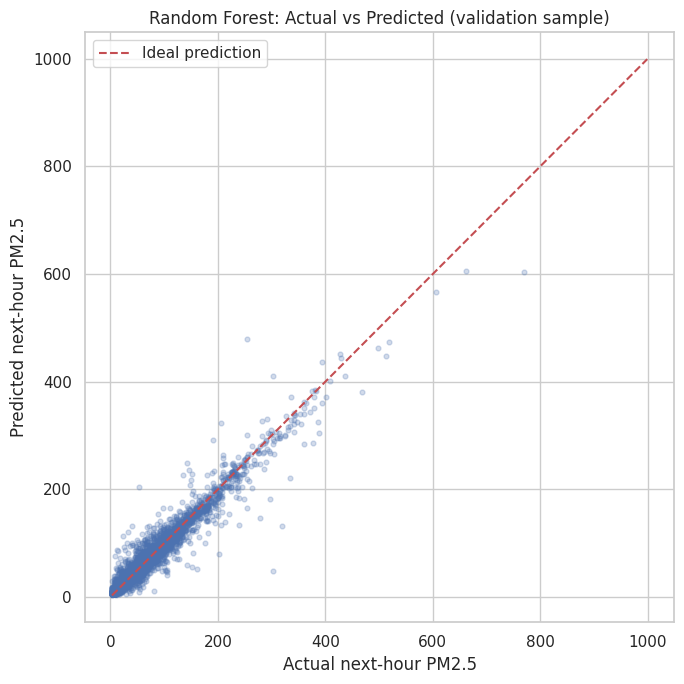

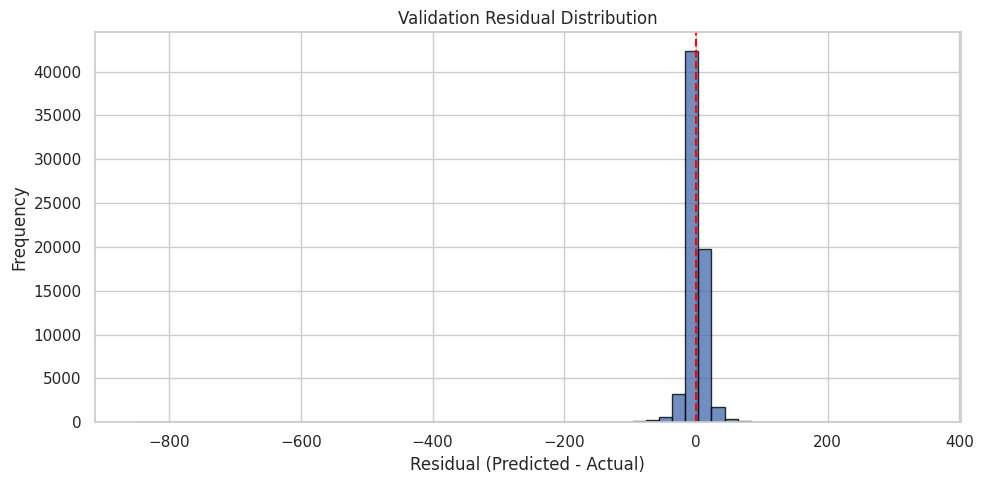

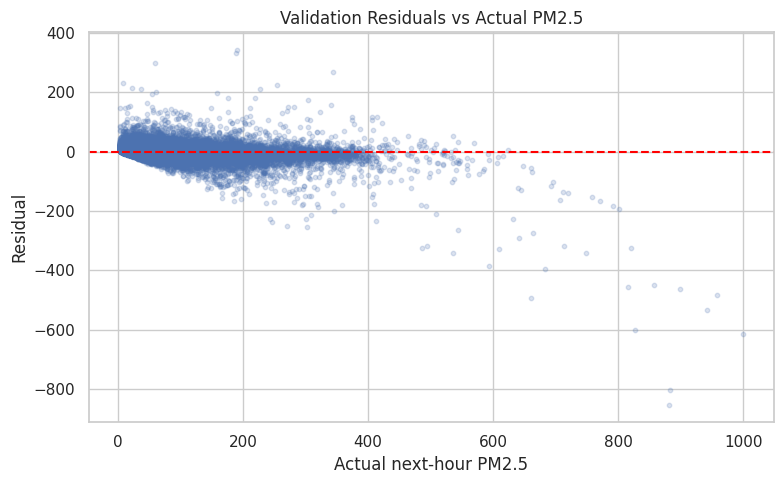

In [ ]:
# Actual vs predicted plot (sample for readability).
rng = np.random.default_rng(RANDOM_STATE)
plot_n = min(5000, len(error_df))
plot_idx = rng.choice(len(error_df), size=plot_n, replace=False)

plt.figure(figsize=(7, 7))
plt.scatter(
    error_df["Actual"].to_numpy()[plot_idx],
    error_df["Predicted"].to_numpy()[plot_idx],
    alpha=0.25,
    s=12
)
lo = min(error_df["Actual"].min(), error_df["Predicted"].min())
hi = max(error_df["Actual"].max(), error_df["Predicted"].max())
plt.plot([lo, hi], [lo, hi], "r--", label="Ideal prediction")
plt.xlabel("Actual next-hour PM2.5")
plt.ylabel("Predicted next-hour PM2.5")
plt.title(f"{FINAL_MODEL_TYPE}: Actual vs Predicted (validation sample)")
plt.legend()
plt.tight_layout()
plt.show()

# Residual distribution
plt.figure(figsize=(10, 5))
plt.hist(error_df["Residual"], bins=60, edgecolor="black", alpha=0.8)
plt.axvline(0, color="red", linestyle="--")
plt.xlabel("Residual (Predicted - Actual)")
plt.ylabel("Frequency")
plt.title("Validation Residual Distribution")
plt.tight_layout()
plt.show()

# Residuals against actual values
plt.figure(figsize=(8, 5))
plt.scatter(error_df["Actual"], error_df["Residual"], alpha=0.2, s=10)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Actual next-hour PM2.5")
plt.ylabel("Residual")
plt.title("Validation Residuals vs Actual PM2.5")
plt.tight_layout()
plt.show()


In [ ]:
# Error by pollution concentration band.
pollution_bins = [-np.inf, 35, 75, 115, 150, np.inf]
pollution_labels = ["0–35", "35–75", "75–115", "115–150", ">150"]

error_df["Pollution_Level"] = pd.cut(
    error_df["Actual"],
    bins=pollution_bins,
    labels=pollution_labels,
    right=False
)

level_error = error_df.groupby("Pollution_Level", observed=False).agg(
    Samples=("Actual", "size"),
    Mean_Actual=("Actual", "mean"),
    Mean_Predicted=("Predicted", "mean"),
    MAE=("Absolute_Error", "mean"),
    Mean_Residual=("Residual", "mean"),
    Median_Residual=("Residual", "median"),
).reset_index()

level_rmse = error_df.groupby("Pollution_Level", observed=False).apply(
    lambda g: np.sqrt(np.mean(g["Residual"] ** 2)),
    include_groups=False
).rename("RMSE").reset_index()

level_error = level_error.merge(level_rmse, on="Pollution_Level", how="left")
display(level_error.round(3))

# Station-wise validation performance
station_error = error_df.groupby("station").apply(
    lambda g: pd.Series({
        "Samples": len(g),
        "MAE": mean_absolute_error(g["Actual"], g["Predicted"]),
        "RMSE": np.sqrt(mean_squared_error(g["Actual"], g["Predicted"])),
        "Mean_Residual": g["Residual"].mean(),
    }),
    include_groups=False
).reset_index()

display(station_error.round(3))
level_error.to_csv(DATA_DIR / "validation_error_by_pollution_level.csv", index=False)
station_error.to_csv(DATA_DIR / "validation_error_by_station.csv", index=False)


,Pollution_Level,Samples,Mean_Actual,Mean_Predicted,MAE,Mean_Residual,Median_Residual,RMSE
0,0–35,29166,15.891,18.537,5.030,2.646,1.537,8.734
1,35–75,19026,53.002,54.623,8.328,1.621,0.656,12.991
2,75–115,10728,92.382,91.151,10.411,-1.231,-1.937,15.592
3,115–150,4674,129.293,125.474,12.373,-3.819,-3.590,18.258
4,>150,5222,228.994,216.468,23.355,-12.527,-8.314,46.367


,station,Samples,MAE,RMSE,Mean_Residual
0,Aotizhongxin,5715.0,8.648,17.305,-0.106
1,Changping,5775.0,7.883,16.945,1.063
2,Dingling,5742.0,8.054,20.199,0.085
3,Dongsi,5583.0,9.097,17.277,-0.390
4,Guanyuan,5759.0,8.427,14.710,0.376
5,Gucheng,5784.0,9.004,16.189,0.173
6,Huairou,5748.0,7.738,16.099,0.370
7,Nongzhanguan,5794.0,8.729,15.374,0.186
8,Shunyi,5654.0,9.387,19.478,-0.618
9,Tiantan,5771.0,8.834,15.523,0.372


In [ ]:
# ============================================
# PERSISTENCE BASELINE COMPARISON
# HANDLE MISSING VALUES SAFELY
# ============================================

# Convert arrays
actual_val = np.asarray(y_val, dtype=float).reshape(-1)
persistence_pred = val_df["PM2.5"].to_numpy(dtype=float)
selected_pred = np.asarray(val_pred_final, dtype=float).reshape(-1)

# Verify row alignment
assert len(actual_val) == len(persistence_pred) == len(selected_pred) == len(val_df)

# Identify rows where both actual target and current PM2.5 are available
valid_mask = (
    np.isfinite(actual_val)
    & np.isfinite(persistence_pred)
)

if not np.isfinite(selected_pred[valid_mask]).all():
    raise ValueError("Non-finite predictions from selected model.")

# Use exactly the same validation observations for both models
y_comparison = actual_val[valid_mask]
persistence_comparison = persistence_pred[valid_mask]
model_comparison = selected_pred[valid_mask]

if len(y_comparison) == 0:
    raise ValueError("No valid observations available for comparison.")

# Calculate metrics
persistence_results = pd.DataFrame([
    {
        "Model": "Persistence baseline",
        "MAE": mean_absolute_error(y_comparison, persistence_comparison),
        "RMSE": np.sqrt(mean_squared_error(y_comparison, persistence_comparison)),
        "R2": r2_score(y_comparison, persistence_comparison),
    },
    {
        "Model": selected_model_name,
        "MAE": mean_absolute_error(y_comparison, model_comparison),
        "RMSE": np.sqrt(mean_squared_error(y_comparison, model_comparison)),
        "R2": r2_score(y_comparison, model_comparison),
    },
])

print("Total validation rows:", len(actual_val))
print("Valid comparison rows:", len(y_comparison))
print("Excluded rows:", len(actual_val) - len(y_comparison))
print("Comparison coverage:", f"{len(y_comparison)/len(actual_val):.2%}")

display(persistence_results.round(4))

Total validation rows: 68816
Valid comparison rows: 68176
Excluded rows: 640
Comparison coverage: 99.07%


,Model,MAE,RMSE,R2
0,Persistence baseline,9.0129,17.6277,0.9245
1,Random Forest,8.5085,16.8073,0.9313


## 23. Final test evaluation — run once after model selection

The test partition has not been used for feature selection or tuning. This cell evaluates the selected final model once on the untouched test period and saves the final artifact and test metrics. Do not change the model based on test results.

In [ ]:
X_test_final = X_test[:, FINAL_FEATURE_INDICES]
test_pred_final = final_model.predict(X_test_final)

final_test_metrics = {
    "MAE": mean_absolute_error(y_test, test_pred_final),
    "RMSE": np.sqrt(mean_squared_error(y_test, test_pred_final)),
    "R2": r2_score(y_test, test_pred_final),
}

print("=" * 55)
print("FINAL AIRCAST TEST RESULTS")
print("=" * 55)
print("Selected model:", selected_model_name)
for metric, value in final_test_metrics.items():
    print(f"{metric}: {value:.4f}")

test_error_df = test_df[["station", "target_datetime", "PM2.5", TARGET]].copy()
test_error_df = test_error_df.rename(columns={TARGET: "Actual"})
test_error_df["Predicted"] = test_pred_final
test_error_df["Residual"] = test_error_df["Predicted"] - test_error_df["Actual"]
test_error_df["Absolute_Error"] = test_error_df["Residual"].abs()

test_metrics_df = pd.DataFrame([{
    "Final_Model": selected_model_name,
    **final_test_metrics,
    "Test_Rows": len(y_test),
}])

display(test_metrics_df.round(4))

# Persist final model metadata and evaluation artifacts.
joblib.dump(final_model, DATA_DIR / "aircast_final_model.joblib")
pd.Series(FINAL_FEATURE_NAMES, name="feature_name").to_csv(
    DATA_DIR / "aircast_final_feature_names.csv", index=False
)
test_metrics_df.to_csv(DATA_DIR / "aircast_final_test_metrics.csv", index=False)
test_error_df.to_csv(DATA_DIR / "aircast_final_test_predictions.csv", index=False)

print("Final model and evaluation files saved to:", DATA_DIR)


FINAL AIRCAST TEST RESULTS
Selected model: Random Forest
MAE: 10.7254
RMSE: 21.3690
R2: 0.9533


,Final_Model,MAE,RMSE,R2,Test_Rows
0,Random Forest,10.7254,21.369,0.9533,51063


Final model and evaluation files saved to: /content/drive/MyDrive/DSA_B11/Majorproject/Dataset


In [ ]:
import gc
import time
import joblib
import numpy as np
import pandas as pd

from pathlib import Path
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --------------------------------------------------
# 1. Evaluate the existing Random Forest baseline
# --------------------------------------------------

rf_path = DATA_DIR / "random_forest_model.joblib"

baseline_model = joblib.load(rf_path)
baseline_pred = baseline_model.predict(X_val)

valid_mask = np.isfinite(y_val) & np.isfinite(baseline_pred)

y_compare = np.asarray(y_val)[valid_mask]
baseline_compare = baseline_pred[valid_mask]

baseline_rmse = np.sqrt(
    mean_squared_error(y_compare, baseline_compare)
)

results = [{
    "Configuration": "Existing Random Forest",
    "MAE": mean_absolute_error(y_compare, baseline_compare),
    "RMSE": baseline_rmse,
    "R2": r2_score(y_compare, baseline_compare)
}]

del baseline_model, baseline_pred
gc.collect()

# --------------------------------------------------
# 2. Define a small search around existing settings
# --------------------------------------------------

rf_candidates = [
    {
        "n_estimators": 150,
        "max_depth": 30,
        "max_features": 0.7,
        "min_samples_leaf": 3,
        "min_samples_split": 9
    },
    {
        "n_estimators": 100,
        "max_depth": 25,
        "max_features": 0.7,
        "min_samples_leaf": 2,
        "min_samples_split": 5
    },
    {
        "n_estimators": 100,
        "max_depth": 35,
        "max_features": 0.7,
        "min_samples_leaf": 3,
        "min_samples_split": 9
    },
    {
        "n_estimators": 100,
        "max_depth": 30,
        "max_features": 0.5,
        "min_samples_leaf": 3,
        "min_samples_split": 9
    }
]

best_candidate_rmse = float("inf")
best_candidate_model = None
best_candidate_params = None

# --------------------------------------------------
# 3. Train and evaluate candidates sequentially
# --------------------------------------------------

for i, params in enumerate(rf_candidates, start=1):

    print(f"\nTraining Random Forest candidate {i}/{len(rf_candidates)}")
    print("Parameters:", params)

    start_time = time.time()

    model = RandomForestRegressor(
        **params,
        random_state=42,
        n_jobs=2
    )

    model.fit(X_train, y_train)

    predictions = model.predict(X_val)
    predictions_compare = predictions[valid_mask]

    mae = mean_absolute_error(y_compare, predictions_compare)
    rmse = np.sqrt(mean_squared_error(y_compare, predictions_compare))
    r2 = r2_score(y_compare, predictions_compare)

    results.append({
        "Configuration": f"RF Candidate {i}",
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(
        f"MAE: {mae:.4f} | RMSE: {rmse:.4f} | "
        f"R2: {r2:.4f} | Time: {time.time()-start_time:.1f}s"
    )

    if rmse < best_candidate_rmse:
        best_candidate_rmse = rmse
        best_candidate_model = model
        best_candidate_params = params.copy()
    else:
        del model

    del predictions
    gc.collect()

# --------------------------------------------------
# 4. Display comparison and save the best candidate
# --------------------------------------------------

rf_tuning_results = pd.DataFrame(results).sort_values(
    "RMSE"
).reset_index(drop=True)

display(rf_tuning_results.round(4))

if best_candidate_rmse < baseline_rmse:

    tuned_rf_path = DATA_DIR / "random_forest_tuned_candidate.joblib"
    joblib.dump(best_candidate_model, tuned_rf_path)

    print("\nA candidate improved upon the existing Random Forest.")
    print("Best parameters:", best_candidate_params)
    print("Saved candidate:", tuned_rf_path)

else:
    print("\nNone of the new candidates outperformed the existing Random Forest.")
    print("The existing Random Forest remains the leading configuration.")

    del best_candidate_model

rf_tuning_results.to_csv(
    DATA_DIR / "random_forest_tuning_results.csv",
    index=False
)

gc.collect()


Training Random Forest candidate 1/4
Parameters: {'n_estimators': 150, 'max_depth': 30, 'max_features': 0.7, 'min_samples_leaf': 3, 'min_samples_split': 9}
MAE: 8.6547 | RMSE: 17.3751 | R2: 0.9269 | Time: 792.4s

Training Random Forest candidate 2/4
Parameters: {'n_estimators': 100, 'max_depth': 25, 'max_features': 0.7, 'min_samples_leaf': 2, 'min_samples_split': 5}
MAE: 8.7101 | RMSE: 17.4626 | R2: 0.9261 | Time: 528.9s

Training Random Forest candidate 3/4
Parameters: {'n_estimators': 100, 'max_depth': 35, 'max_features': 0.7, 'min_samples_leaf': 3, 'min_samples_split': 9}
MAE: 8.6729 | RMSE: 17.3280 | R2: 0.9272 | Time: 548.2s

Training Random Forest candidate 4/4
Parameters: {'n_estimators': 100, 'max_depth': 30, 'max_features': 0.5, 'min_samples_leaf': 3, 'min_samples_split': 9}
MAE: 8.6597 | RMSE: 17.5875 | R2: 0.9251 | Time: 372.6s


,Configuration,MAE,RMSE,R2
0,RF Candidate 3,8.6729,17.3280,0.9272
1,RF Candidate 1,8.6547,17.3751,0.9269
2,Existing Random Forest,8.6702,17.3976,0.9267
3,RF Candidate 2,8.7101,17.4626,0.9261
4,RF Candidate 4,8.6597,17.5875,0.9251



A candidate improved upon the existing Random Forest.
Best parameters: {'n_estimators': 100, 'max_depth': 35, 'max_features': 0.7, 'min_samples_leaf': 3, 'min_samples_split': 9}
Saved candidate: /content/drive/MyDrive/DSA_B11/Majorproject/Dataset/random_forest_tuned_candidate.joblib


0

In [ ]:
import joblib
import numpy as np
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tuned_path = DATA_DIR / "random_forest_tuned_candidate.joblib"

tuned_rf = joblib.load(tuned_path)

tuned_pred = tuned_rf.predict(X_val)

valid_mask = np.isfinite(y_val) & np.isfinite(tuned_pred)

y_check = np.asarray(y_val)[valid_mask]
pred_check = tuned_pred[valid_mask]

print("Tuned Random Forest Validation Results")
print("--------------------------------------")
print("MAE :", round(mean_absolute_error(y_check, pred_check), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_check, pred_check)), 4))
print("R2  :", round(r2_score(y_check, pred_check), 4))

print("\nModel parameters:")
print(tuned_rf.get_params())

print("\nModel verification completed.")

Tuned Random Forest Validation Results
--------------------------------------
MAE : 8.6729
RMSE: 17.328
R2  : 0.9272

Model parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'criterion': 'squared_error', 'max_depth': 35, 'max_features': 0.7, 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 3, 'min_samples_split': 9, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 100, 'n_jobs': 2, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}

Model verification completed.


PREDICTION ERROR ANALYSIS
Total validation observations: 68816
Valid observations: 68816
Excluded observations: 0

Error Statistics:


,Error,Absolute_Error
count,68816.000,68816.000
mean,-0.173,8.673
std,17.327,15.001
min,-324.999,0.000
25%,-5.252,2.132
50%,-0.548,4.887
75%,4.469,10.151
max,853.108,853.108



Prediction Bias:
Mean Error: -0.173
Mean Absolute Error: 8.6729

Interpretation:
Positive error = Model underprediction
Negative error = Model overprediction


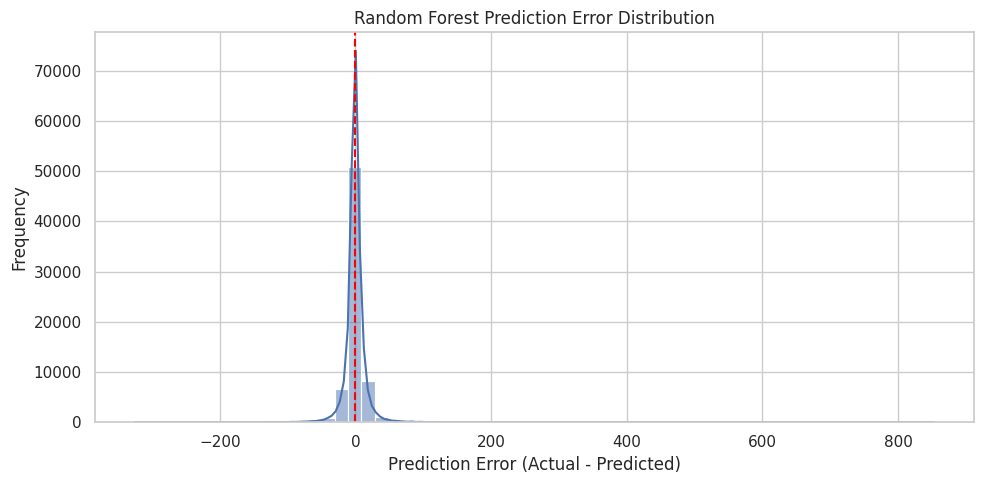

88

In [ ]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import gc

# Load tuned Random Forest
tuned_rf_path = DATA_DIR / "random_forest_tuned_candidate.joblib"
tuned_rf = joblib.load(tuned_rf_path)

# Generate validation predictions
val_predictions = tuned_rf.predict(X_val)

# Prepare actual and predicted values
actual = np.asarray(y_val, dtype=float).reshape(-1)
predicted = np.asarray(val_predictions, dtype=float).reshape(-1)

# Verify alignment
assert len(actual) == len(predicted), "Prediction alignment error!"

# Remove invalid observations
valid_mask = np.isfinite(actual) & np.isfinite(predicted)

error_df = pd.DataFrame({
    "Actual_PM2.5": actual[valid_mask],
    "Predicted_PM2.5": predicted[valid_mask]
})

# Calculate prediction errors
error_df["Error"] = (
    error_df["Actual_PM2.5"] -
    error_df["Predicted_PM2.5"]
)

error_df["Absolute_Error"] = error_df["Error"].abs()

# Display summary
print("PREDICTION ERROR ANALYSIS")
print("=" * 50)

print("Total validation observations:", len(actual))
print("Valid observations:", len(error_df))
print("Excluded observations:", len(actual) - len(error_df))

print("\nError Statistics:")
display(error_df[["Error", "Absolute_Error"]].describe().round(3))

print("\nPrediction Bias:")
print("Mean Error:", round(error_df["Error"].mean(), 4))
print("Mean Absolute Error:", round(error_df["Absolute_Error"].mean(), 4))

print("\nInterpretation:")
print("Positive error = Model underprediction")
print("Negative error = Model overprediction")

# Plot error distribution
plt.figure(figsize=(10, 5))
sns.histplot(error_df["Error"], bins=60, kde=True)
plt.axvline(0, linestyle="--", color="red")
plt.title("Random Forest Prediction Error Distribution")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

gc.collect()

In [ ]:
# Verify row alignment with validation dataset
assert len(error_df) == len(val_df), "Validation row alignment mismatch!"

# Attach validation metadata
error_analysis_df = error_df.copy().reset_index(drop=True)
metadata = val_df.reset_index(drop=True)

# Add useful columns if available
metadata_columns = [
    "station", "datetime", "date",
    "year", "month", "day", "hour",
    "PM2.5", "PM10", "TEMP", "WSPM"
]

for col in metadata_columns:
    if col in metadata.columns:
        error_analysis_df[col] = metadata[col]

# Sort by largest absolute prediction error
worst_predictions = error_analysis_df.sort_values(
    "Absolute_Error",
    ascending=False
)

print("TOP 20 LARGEST PREDICTION ERRORS")
print("=" * 70)

display(
    worst_predictions.head(20).round(3)
)

# Examine actual PM2.5 values for these observations
print("\nACTUAL PM2.5 STATISTICS")
display(
    error_analysis_df["Actual_PM2.5"].describe(
        percentiles=[0.90, 0.95, 0.99, 0.999]
    ).round(3)
)

# Count observations with very large errors
print("\nLARGE ERROR COUNTS")

for threshold in [25, 50, 100, 200]:
    count = (
        error_analysis_df["Absolute_Error"] > threshold
    ).sum()

    print(
        f"Errors greater than {threshold}: "
        f"{count} ({count / len(error_analysis_df) * 100:.3f}%)"
    )

TOP 20 LARGEST PREDICTION ERRORS


,Actual_PM2.5,Predicted_PM2.5,Error,Absolute_Error,station,datetime,year,month,day,hour,PM2.5,PM10,TEMP,WSPM
10863,881.0,27.892,853.108,853.108,Dingling,2016-02-08 00:00:00,2016,2,8,0,28.0,48.0,-1.1,1.8
10873,882.0,82.134,799.866,799.866,Changping,2016-02-08 01:00:00,2016,2,8,1,NaN,NaN,-1.5,1.3
10871,826.0,219.974,606.026,606.026,Wanshouxigong,2016-02-08 00:00:00,2016,2,8,0,238.0,340.0,-1.5,0.2
10883,999.0,414.257,584.743,584.743,Wanshouxigong,2016-02-08 01:00:00,2016,2,8,1,826.0,NaN,-1.7,1.5
10880,941.0,429.974,511.026,511.026,Shunyi,2016-02-08 01:00:00,2016,2,8,1,816.0,NaN,-3.9,1.1
10864,661.0,173.340,487.660,487.660,Dongsi,2016-02-08 00:00:00,2016,2,8,0,169.0,397.0,-1.5,0.2
10882,957.0,484.785,472.215,472.215,Wanliu,2016-02-08 01:00:00,2016,2,8,1,593.0,712.0,-3.3,1.0
10868,816.0,346.513,469.487,469.487,Shunyi,2016-02-08 00:00:00,2016,2,8,0,407.0,469.0,-3.9,0.6
10872,898.0,447.244,450.756,450.756,Aotizhongxin,2016-02-08 01:00:00,2016,2,8,1,494.0,637.0,-1.7,1.5
10895,857.0,420.241,436.759,436.759,Wanshouxigong,2016-02-08 02:00:00,2016,2,8,2,999.0,NaN,-1.6,1.1



ACTUAL PM2.5 STATISTICS


,Actual_PM2.5
count,68816.000
mean,61.949
std,64.243
min,3.000
50%,44.000
90%,133.000
95%,181.000
99%,315.000
99.9%,520.370
max,999.000



LARGE ERROR COUNTS
Errors greater than 25: 4250 (6.176%)
Errors greater than 50: 1028 (1.494%)
Errors greater than 100: 214 (0.311%)
Errors greater than 200: 43 (0.062%)


In [ ]:
# Copy error analysis data
episode_df = error_analysis_df.copy()

# Convert datetime
episode_df["datetime"] = pd.to_datetime(
    episode_df["datetime"]
)

# Target represents the next-hour PM2.5
episode_df["Target_Time"] = (
    episode_df["datetime"] + pd.Timedelta(hours=1)
)

# Inspect February 8, 2016, from 00:00 to 03:00
episode = episode_df[
    (episode_df["datetime"] >= "2016-02-08 00:00:00") &
    (episode_df["datetime"] <= "2016-02-08 03:00:00")
].copy()

columns_to_show = [
    "station",
    "datetime",
    "Target_Time",
    "Actual_PM2.5",
    "Predicted_PM2.5",
    "Error",
    "PM2.5",
    "PM10"
]

columns_to_show = [
    col for col in columns_to_show
    if col in episode.columns
]

print("EXTREME POLLUTION EPISODE")
print("=" * 65)
print("Number of observations:", len(episode))
print("Number of stations:", episode["station"].nunique())

display(
    episode[columns_to_show]
    .sort_values(["datetime", "station"])
    .round(2)
)

# --------------------------------------------------
# Examine extreme target values
# --------------------------------------------------

print("\nEXTREME TARGET VALUE ANALYSIS")
print("=" * 65)

for threshold in [300, 500, 800, 900, 999]:
    count = (
        error_analysis_df["Actual_PM2.5"] >= threshold
    ).sum()

    print(
        f"Target PM2.5 >= {threshold}: "
        f"{count} observations"
    )

print(
    "\nExact target value of 999:",
    (error_analysis_df["Actual_PM2.5"] == 999).sum()
)

# --------------------------------------------------
# Error performance during high pollution
# --------------------------------------------------

print("\nMODEL PERFORMANCE BY POLLUTION LEVEL")
print("=" * 65)

for threshold in [150, 300, 500]:
    subset = error_analysis_df[
        error_analysis_df["Actual_PM2.5"] >= threshold
    ]

    if len(subset) > 0:
        print(
            f"\nActual PM2.5 >= {threshold} "
            f"(n={len(subset)})"
        )
        print(
            "MAE:",
            round(subset["Absolute_Error"].mean(), 3)
        )
        print(
            "RMSE:",
            round(
                np.sqrt(np.mean(subset["Error"] ** 2)),
                3
            )
        )

EXTREME POLLUTION EPISODE
Number of observations: 46
Number of stations: 12


,station,datetime,Target_Time,Actual_PM2.5,Predicted_PM2.5,Error,PM2.5,PM10
10862,Aotizhongxin,2016-02-08 00:00:00,2016-02-08 01:00:00,494.0,177.47,316.53,152.0,230.0
10863,Dingling,2016-02-08 00:00:00,2016-02-08 01:00:00,881.0,27.89,853.11,28.0,48.0
10864,Dongsi,2016-02-08 00:00:00,2016-02-08 01:00:00,661.0,173.34,487.66,169.0,397.0
10865,Guanyuan,2016-02-08 00:00:00,2016-02-08 01:00:00,486.0,164.08,321.92,170.0,271.0
10866,Huairou,2016-02-08 00:00:00,2016-02-08 01:00:00,683.0,306.71,376.29,309.0,358.0
10867,Nongzhanguan,2016-02-08 00:00:00,2016-02-08 01:00:00,413.0,175.31,237.69,172.0,237.0
10868,Shunyi,2016-02-08 00:00:00,2016-02-08 01:00:00,816.0,346.51,469.49,407.0,469.0
10869,Tiantan,2016-02-08 00:00:00,2016-02-08 01:00:00,296.0,171.59,124.41,151.0,215.0
10870,Wanliu,2016-02-08 00:00:00,2016-02-08 01:00:00,593.0,209.72,383.28,209.0,281.0
10871,Wanshouxigong,2016-02-08 00:00:00,2016-02-08 01:00:00,826.0,219.97,606.03,238.0,340.0



EXTREME TARGET VALUE ANALYSIS
Target PM2.5 >= 300: 838 observations
Target PM2.5 >= 500: 82 observations
Target PM2.5 >= 800: 11 observations
Target PM2.5 >= 900: 3 observations
Target PM2.5 >= 999: 1 observations

Exact target value of 999: 1

MODEL PERFORMANCE BY POLLUTION LEVEL

Actual PM2.5 >= 150 (n=5222)
MAE: 23.309
RMSE: 45.944

Actual PM2.5 >= 300 (n=838)
MAE: 40.005
RMSE: 88.36

Actual PM2.5 >= 500 (n=82)
MAE: 154.43
RMSE: 243.533


In [ ]:
import pandas as pd
import numpy as np

# Load target-prepared dataset
raw_check = pd.read_csv(
    DATA_DIR / "beijing_air_quality_target_prepared.csv"
)

raw_check["datetime"] = pd.to_datetime(raw_check["datetime"])

# --------------------------------------------------
# 1. Check original PM2.5 values
# --------------------------------------------------

print("ORIGINAL DATASET EXTREME VALUE CHECK")
print("=" * 60)

print("Total rows:", len(raw_check))
print("PM2.5 values equal to 999:",
      (raw_check["PM2.5"] == 999).sum())

print("PM2.5 values >= 500:",
      (raw_check["PM2.5"] >= 500).sum())

print("\nHighest original PM2.5 values:")
display(
    raw_check.nlargest(15, "PM2.5")[
        ["station", "datetime", "PM2.5"]
    ]
)

# --------------------------------------------------
# 2. Inspect the February 8 pollution episode
# --------------------------------------------------

episode_raw = raw_check[
    (raw_check["datetime"] >= "2016-02-07 23:00:00") &
    (raw_check["datetime"] <= "2016-02-08 04:00:00")
].copy()

print("\nORIGINAL READINGS DURING THE POLLUTION EPISODE")
print("=" * 60)

display(
    episode_raw[
        ["station", "datetime", "PM2.5", "PM2.5_next_hour"]
    ].sort_values(["datetime", "station"]).round(2)
)

# --------------------------------------------------
# 3. Verify next-hour target construction
# --------------------------------------------------

raw_check = raw_check.sort_values(
    ["station", "datetime"]
).reset_index(drop=True)

raw_check["Next_Datetime"] = (
    raw_check.groupby("station")["datetime"].shift(-1)
)

raw_check["Next_Actual_PM2.5"] = (
    raw_check.groupby("station")["PM2.5"].shift(-1)
)

exact_next_hour = (
    raw_check["Next_Datetime"] ==
    raw_check["datetime"] + pd.Timedelta(hours=1)
)

valid_target = (
    exact_next_hour &
    raw_check["PM2.5_next_hour"].notna()
)

target_match = np.isclose(
    raw_check.loc[valid_target, "PM2.5_next_hour"],
    raw_check.loc[valid_target, "Next_Actual_PM2.5"]
)

print("\nTARGET CONSTRUCTION VERIFICATION")
print("=" * 60)
print("Rows with exact next-hour observations:", valid_target.sum())
print("Matching target values:", target_match.sum())
print("Mismatching target values:", (~target_match).sum())

# --------------------------------------------------
# 4. Check the extreme episode's target consistency
# --------------------------------------------------

event_check = raw_check[
    (raw_check["datetime"] >= "2016-02-08 00:00:00") &
    (raw_check["datetime"] <= "2016-02-08 03:00:00")
].copy()

event_check["Target_Matches_Next_Hour"] = np.isclose(
    event_check["PM2.5_next_hour"],
    event_check["Next_Actual_PM2.5"],
    equal_nan=True
)

print("\nEVENT TARGET CONSISTENCY")
display(
    event_check[
        [
            "station", "datetime", "PM2.5",
            "PM2.5_next_hour",
            "Next_Actual_PM2.5",
            "Target_Matches_Next_Hour"
        ]
    ].round(2)
)

ORIGINAL DATASET EXTREME VALUE CHECK
Total rows: 412017
PM2.5 values equal to 999: 1
PM2.5 values >= 500: 940

Highest original PM2.5 values:


,station,datetime,PM2.5
303033,Wanshouxigong,2016-02-08 02:00:00,999.0
303032,Wanliu,2016-02-08 02:00:00,957.0
303030,Shunyi,2016-02-08 02:00:00,941.0
303022,Aotizhongxin,2016-02-08 02:00:00,898.0
303023,Changping,2016-02-08 02:00:00,882.0
303012,Dingling,2016-02-08 01:00:00,881.0
303045,Wanshouxigong,2016-02-08 03:00:00,857.0
18723,Nongzhanguan,2013-05-05 12:00:00,844.0
403067,Nongzhanguan,2017-01-28 02:00:00,835.0
303021,Wanshouxigong,2016-02-08 01:00:00,826.0



ORIGINAL READINGS DURING THE POLLUTION EPISODE


,station,datetime,PM2.5,PM2.5_next_hour
302989,Aotizhongxin,2016-02-07 23:00:00,61.0,152.0
302990,Dingling,2016-02-07 23:00:00,27.0,28.0
302991,Dongsi,2016-02-07 23:00:00,120.0,169.0
302992,Guanyuan,2016-02-07 23:00:00,145.0,170.0
302993,Gucheng,2016-02-07 23:00:00,246.0,409.0
...,...,...,...,...
303053,Nongzhanguan,2016-02-08 04:00:00,566.0,558.0
303054,Shunyi,2016-02-08 04:00:00,707.0,536.0
303055,Tiantan,2016-02-08 04:00:00,801.0,758.0
303056,Wanliu,2016-02-08 04:00:00,791.0,770.0



TARGET CONSTRUCTION VERIFICATION
Rows with exact next-hour observations: 409168
Matching target values: 409168
Mismatching target values: 0

EVENT TARGET CONSISTENCY


,station,datetime,PM2.5,PM2.5_next_hour,Next_Actual_PM2.5,Target_Matches_Next_Hour
25034,Aotizhongxin,2016-02-08 00:00:00,152.0,494.0,494.0,True
25035,Aotizhongxin,2016-02-08 01:00:00,494.0,898.0,898.0,True
25036,Aotizhongxin,2016-02-08 02:00:00,898.0,713.0,713.0,True
25037,Aotizhongxin,2016-02-08 03:00:00,713.0,615.0,615.0,True
59258,Changping,2016-02-08 01:00:00,NaN,882.0,882.0,True
59259,Changping,2016-02-08 02:00:00,882.0,485.0,485.0,True
59260,Changping,2016-02-08 03:00:00,485.0,405.0,405.0,True
93715,Dingling,2016-02-08 00:00:00,28.0,881.0,881.0,True
93716,Dingling,2016-02-08 01:00:00,881.0,610.0,610.0,True
93717,Dingling,2016-02-08 02:00:00,610.0,189.0,189.0,True


STATION-WISE MODEL PERFORMANCE


,Station,Observations,MAE,RMSE,R2,Mean_Error
0,Guanyuan,5759,8.4159,14.6744,0.9482,-0.3692
1,Nongzhanguan,5794,8.7284,15.4005,0.9440,-0.1166
2,Tiantan,5771,8.8804,15.6820,0.9379,-0.3969
3,Huairou,5748,7.7608,15.8786,0.9231,-0.3609
4,Gucheng,5784,9.0472,16.2837,0.9352,-0.2189
5,Changping,5775,7.8877,16.9037,0.9010,-1.0540
6,Aotizhongxin,5715,8.6300,17.0854,0.9345,0.0947
7,Dongsi,5583,9.1362,17.2899,0.9366,0.3623
8,Wanliu,5791,8.6261,17.4085,0.9285,-0.6149
9,Shunyi,5654,9.3691,19.3711,0.9240,0.6160


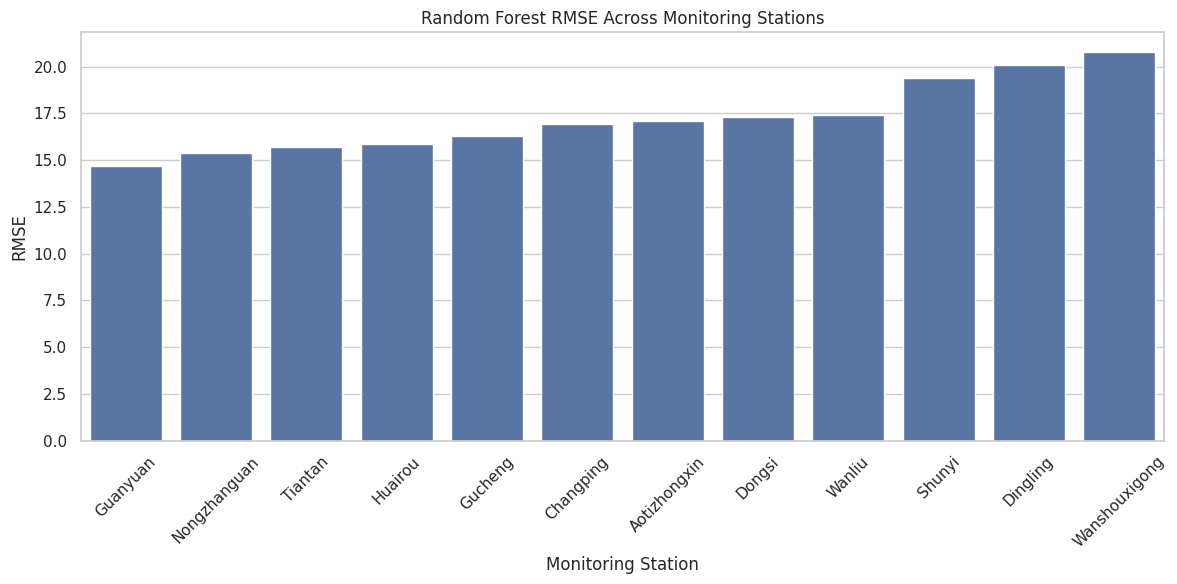


BEST PERFORMING STATION:
Station          Guanyuan
Observations         5759
MAE              8.415851
RMSE            14.674395
R2               0.948228
Mean_Error      -0.369156

WORST PERFORMING STATION:
Station         Wanshouxigong
Observations             5700
MAE                  9.595333
RMSE                20.789025
R2                   0.904312
Mean_Error           0.095524


In [ ]:
# Group validation predictions by station

station_results = []

for station, group in error_analysis_df.groupby("station"):

    actual_station = group["Actual_PM2.5"].to_numpy()
    predicted_station = group["Predicted_PM2.5"].to_numpy()

    station_results.append({
        "Station": station,
        "Observations": len(group),
        "MAE": mean_absolute_error(
            actual_station, predicted_station
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual_station, predicted_station
            )
        ),
        "R2": r2_score(
            actual_station, predicted_station
        ),
        "Mean_Error": group["Error"].mean()
    })

station_results_df = pd.DataFrame(
    station_results
).sort_values("RMSE", ascending=True).reset_index(drop=True)

print("STATION-WISE MODEL PERFORMANCE")
print("=" * 70)

display(station_results_df.round(4))

# Visualize RMSE by station
plt.figure(figsize=(12, 6))

sns.barplot(
    data=station_results_df,
    x="Station",
    y="RMSE"
)

plt.title("Random Forest RMSE Across Monitoring Stations")
plt.xlabel("Monitoring Station")
plt.ylabel("RMSE")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Best and worst stations
print("\nBEST PERFORMING STATION:")
print(station_results_df.iloc[0].to_string())

print("\nWORST PERFORMING STATION:")
print(station_results_df.iloc[-1].to_string())

POLLUTION CATEGORY-WISE MODEL PERFORMANCE


,Pollution_Category,Observations,Percentage,MAE,RMSE,Mean_Error
0,Low,29166,42.3826,5.0231,8.7227,-2.6427
1,Moderate,19026,27.6476,8.3328,12.9999,-1.6371
2,High,15402,22.3814,11.0423,16.5242,2.0217
3,Very High,4384,6.3706,20.1174,31.9670,9.3711
4,Extreme,838,1.2177,40.0054,88.3601,28.7551


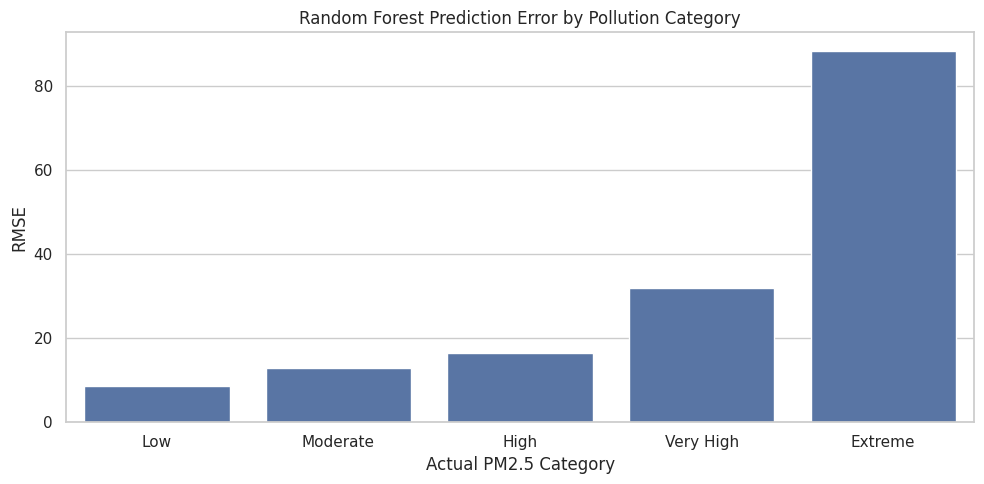

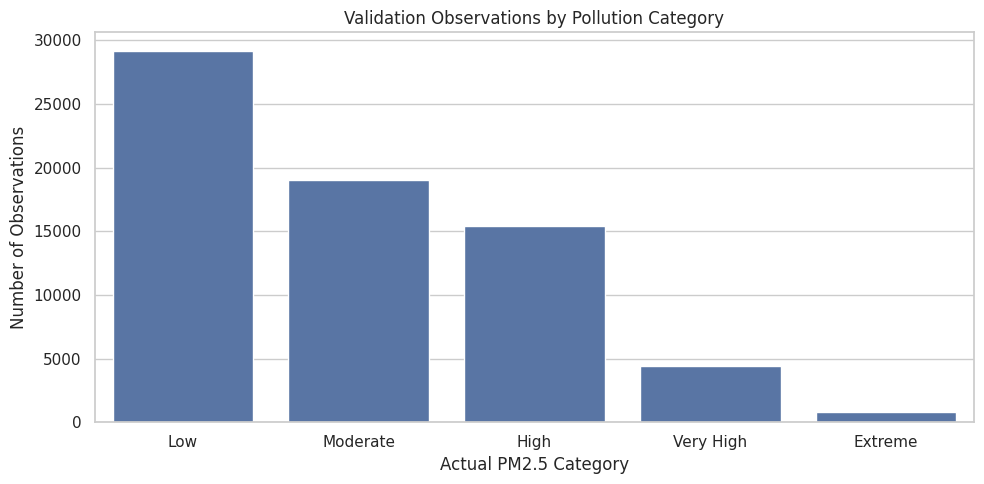

In [ ]:
# Create pollution categories using actual next-hour PM2.5
pollution_df = error_analysis_df.copy()

bins = [0, 35, 75, 150, 300, np.inf]

labels = [
    "Low",
    "Moderate",
    "High",
    "Very High",
    "Extreme"
]

pollution_df["Pollution_Category"] = pd.cut(
    pollution_df["Actual_PM2.5"],
    bins=bins,
    labels=labels,
    right=False
)

# Calculate performance for each category
category_results = []

for category in labels:

    group = pollution_df[
        pollution_df["Pollution_Category"] == category
    ]

    if len(group) == 0:
        continue

    category_results.append({
        "Pollution_Category": category,
        "Observations": len(group),
        "Percentage": len(group) / len(pollution_df) * 100,
        "MAE": group["Absolute_Error"].mean(),
        "RMSE": np.sqrt(
            np.mean(group["Error"] ** 2)
        ),
        "Mean_Error": group["Error"].mean()
    })

category_results_df = pd.DataFrame(
    category_results
)

print("POLLUTION CATEGORY-WISE MODEL PERFORMANCE")
print("=" * 75)

display(category_results_df.round(4))

# Visualize RMSE by pollution category
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_results_df,
    x="Pollution_Category",
    y="RMSE"
)

plt.title("Random Forest Prediction Error by Pollution Category")
plt.xlabel("Actual PM2.5 Category")
plt.ylabel("RMSE")
plt.tight_layout()
plt.show()

# Visualize observation distribution
plt.figure(figsize=(10, 5))

sns.barplot(
    data=category_results_df,
    x="Pollution_Category",
    y="Observations"
)

plt.title("Validation Observations by Pollution Category")
plt.xlabel("Actual PM2.5 Category")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import joblib
import gc

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# --------------------------------------------------
# 1. Load the selected tuned Random Forest
# --------------------------------------------------

final_model_path = (
    DATA_DIR / "random_forest_tuned_candidate.joblib"
)

final_model = joblib.load(final_model_path)

# --------------------------------------------------
# 2. Generate test predictions ONCE
# --------------------------------------------------

test_predictions = final_model.predict(X_test)

y_test_array = np.asarray(y_test, dtype=float).reshape(-1)
test_predictions = np.asarray(
    test_predictions, dtype=float
).reshape(-1)

assert len(y_test_array) == len(test_predictions)

valid_mask = (
    np.isfinite(y_test_array) &
    np.isfinite(test_predictions)
)

actual_test = y_test_array[valid_mask]
predicted_test = test_predictions[valid_mask]

# --------------------------------------------------
# 3. Calculate final test metrics
# --------------------------------------------------

test_mae = mean_absolute_error(
    actual_test, predicted_test
)

test_rmse = np.sqrt(
    mean_squared_error(actual_test, predicted_test)
)

test_r2 = r2_score(
    actual_test, predicted_test
)

print("FINAL RANDOM FOREST TEST RESULTS")
print("=" * 55)

print("Total test observations:", len(y_test_array))
print("Valid test observations:", len(actual_test))

print("\nMAE :", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R2  :", round(test_r2, 4))

# --------------------------------------------------
# 4. Compare with persistence baseline
# --------------------------------------------------

test_current_pm25 = test_df["PM2.5"].to_numpy(dtype=float)

baseline_mask = (
    valid_mask &
    np.isfinite(test_current_pm25)
)

actual_common = y_test_array[baseline_mask]
model_common = test_predictions[baseline_mask]
persistence_common = test_current_pm25[baseline_mask]

comparison_results = pd.DataFrame([
    {
        "Model": "Tuned Random Forest",
        "MAE": mean_absolute_error(
            actual_common, model_common
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual_common, model_common
            )
        ),
        "R2": r2_score(actual_common, model_common)
    },
    {
        "Model": "Persistence Baseline",
        "MAE": mean_absolute_error(
            actual_common, persistence_common
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual_common, persistence_common
            )
        ),
        "R2": r2_score(
            actual_common, persistence_common
        )
    }
])

print("\nTEST PERFORMANCE COMPARISON")
print("=" * 55)
print("Common valid observations:", len(actual_common))

display(comparison_results.round(4))

# --------------------------------------------------
# 5. Save final test predictions and metrics
# --------------------------------------------------

test_output = pd.DataFrame({
    "Actual_PM2.5": y_test_array,
    "Predicted_PM2.5": test_predictions
})

test_output["Error"] = (
    test_output["Actual_PM2.5"] -
    test_output["Predicted_PM2.5"]
)

test_output["Absolute_Error"] = (
    test_output["Error"].abs()
)

test_output.to_csv(
    DATA_DIR / "final_test_predictions.csv",
    index=False
)

comparison_results.to_csv(
    DATA_DIR / "final_test_metrics.csv",
    index=False
)

print("\nSaved:")
print("final_test_predictions.csv")
print("final_test_metrics.csv")

gc.collect()

FINAL RANDOM FOREST TEST RESULTS
Total test observations: 51063
Valid test observations: 51063

MAE : 10.7401
RMSE: 21.3596
R2  : 0.9533

TEST PERFORMANCE COMPARISON
Common valid observations: 50692


,Model,MAE,RMSE,R2
0,Tuned Random Forest,10.6334,21.1440,0.9544
1,Persistence Baseline,11.4957,22.9035,0.9465



Saved:
final_test_predictions.csv
final_test_metrics.csv


6769

In [1]:
import sys
import numpy as np
import pandas as pd
import sklearn
import joblib

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
Joblib: 1.6.0
